# Diagnosing stitched focal and gap matches

Compare the saved full HMM and stitched paths for a simulated dataset and
chromosome 20 from 1KGP. The stitched path combines **retained exact focal
pieces** with **independent full-reference gap fills**. In this notebook,
"gap fill" refers to the replaced regions, while "stitched" means the complete
combined path. All parents are original-reference node IDs.

Questions:
1. Which focal pieces and gap fills agree with the full HMM parent path?
2. Where do the additional switches occur: inside focal pieces, inside gaps,
   or at the seams between them?
3. Can we inspect both successful and unsuccessful gap fills, and focal pieces
   that already differ from the full path?

Settings and deep-dive identities live in
the scientific settings cell below. The notebook reads existing
outputs and copied references; it does not rerun matching or change its inputs.
Edit this `.py` file and use Jupytext to synchronize the paired notebook.

In [1]:
import dataclasses
import logging
import pathlib

import IPython.display as ipython_display
import numpy as np
import pandas as pd

from ch5 import nb_plot, nb_utils

repository_dir = pathlib.Path.cwd()
logger = logging.getLogger(__name__)

In [2]:
repository_dir = pathlib.Path.cwd()
diagnostic_config_path = {
    "datasets": [
        {
            "name": "out_of_africa_n100_10mbp",
            "label": "Simulation, 100 individuals, 10 Mb",
            "deep_dive": {"sample_id": "tsk_18", "ploidy_index": 0},
            "haplotypes": [
                {"sample_id": "tsk_18", "ploidy_index": 0},
                {"sample_id": "tsk_40", "ploidy_index": 1},
                {"sample_id": "tsk_96", "ploidy_index": 1},
            ],
            "populations": ["YRI", "CEU", "CHB"],
        },
        {
            "name": "tgp_chr20_n100",
            "label": "1KGP chromosome 20, 100 individuals, 10 Mb",
            "deep_dive": {"sample_id": "NA18582", "ploidy_index": 0},
            "haplotypes": [
                {"sample_id": "NA07019", "ploidy_index": 1},
                {"sample_id": "NA18582", "ploidy_index": 0},
                {"sample_id": "NA19150", "ploidy_index": 0},
            ],
            "populations": ["AFR", "EUR", "EAS"],
        },
    ],
    "detail": {"context_sites": 25, "max_sites": 240, "min_agreement_gap_sites": 5},
    "outliers": {
        "output_dir": repository_dir / "data/ch5/stitching_outliers",
        "criteria": [
            {
                "metric": "num_extra_switches",
                "label": "Most extra switches",
                "ascending": False,
            },
            {
                "metric": "focal_agreement_percentage",
                "label": "Lowest focal agreement",
                "ascending": True,
            },
            {
                "metric": "gap_agreement_percentage",
                "label": "Lowest gap agreement",
                "ascending": True,
            },
        ],
        "short_gap_max_sites": 10,
        "short_gap_site_axis": True,
        "gaps_to_display": 8,
        "divergences_to_display": 8,
        "max_windows_per_haplotype": 5,
    },
    "distance_bin_edges": [0, 1, 2, 5, 10, 20, 50, 100, 250, 500, 1000, 5000, 100000],
    "cohort": {
        "num_haplotypes": 200,
        "num_individuals": 100,
        "output_dir": repository_dir / "data/ch5/stitching_cohort",
    },
}
diagnostic_config_path["base_dir"] = repository_dir
config = diagnostic_config_path
experiment_config = {
    "input_dir": repository_dir / "data/ch5/match_eval",
    "coverage_input_dir": repository_dir.parent / "tsinfer-match-eval/data/match_eval",
    "output_dir": repository_dir / "data/ch5/chunk_matching_experiment",
    "ac_cutoff": 10,
    "min_focal_ac": 2,
    "workers": None,
    "score_tolerance": 1e-08,
    "datasets": [
        {"name": "out_of_africa_n100_10mbp", "haplotypes": None},
        {"name": "tgp_chr20_n100", "haplotypes": None},
    ],
}
input_dir = pathlib.Path(experiment_config["input_dir"]).expanduser()
output_dir = pathlib.Path(experiment_config["output_dir"]).expanduser()
if not input_dir.is_absolute():
    input_dir = repository_dir / input_dir
if not output_dir.is_absolute():
    output_dir = repository_dir / output_dir
coverage_input_dir = pathlib.Path(experiment_config["coverage_input_dir"]).expanduser()
gap_comparison_dir = (
    repository_dir / "data/ch5/stitching_gap_diagnostics"
).expanduser()
if not coverage_input_dir.is_absolute():
    coverage_input_dir = repository_dir / coverage_input_dir
if not gap_comparison_dir.is_absolute():
    gap_comparison_dir = repository_dir / gap_comparison_dir
nb_plot.configure_notebook({"figure.dpi": 120, "font.size": 10})
diagnosing_stitched_focal_and_gap_matches_result = nb_plot.make_path_colormaps()
category_cmap = diagnosing_stitched_focal_and_gap_matches_result.category_cmap
category_norm = diagnosing_stitched_focal_and_gap_matches_result.category_norm
source_cmap = diagnosing_stitched_focal_and_gap_matches_result.source_cmap
source_norm = diagnosing_stitched_focal_and_gap_matches_result.source_norm

In [3]:
datasets = [
    nb_utils.load_dataset(
        settings,
        experiment_config=experiment_config,
        input_dir=input_dir,
        output_dir=output_dir,
        plot_terminal_site_width_bp=1,
    )
    for settings in config["datasets"]
]
summary = pd.DataFrame([case.summary for dataset in datasets for case in dataset.cases])
summary["focal_agreement_fraction"] = (
    1 - summary.accepted_disagreement_sites / summary.accepted_sites
)
summary["gap_agreement_fraction"] = (
    1 - summary.gap_disagreement_sites / summary.gap_sites
)
ipython_display.display(
    summary[
        [
            "dataset",
            "sample_id",
            "ploidy_index",
            "num_focal_ancestors",
            "accepted_sites",
            "gap_sites",
            "num_gaps",
            "fraction_parent_agreement",
            "focal_agreement_fraction",
            "gap_agreement_fraction",
            "full_switches",
            "stitched_switches",
            "num_extra_switches",
            "extra_switch_fraction",
            "full_mismatches",
            "stitched_mismatches",
        ]
    ].round(4)
)

,dataset,sample_id,ploidy_index,num_focal_ancestors,accepted_sites,gap_sites,num_gaps,fraction_parent_agreement,focal_agreement_fraction,gap_agreement_fraction,full_switches,stitched_switches,num_extra_switches,extra_switch_fraction,full_mismatches,stitched_mismatches
0,out_of_africa_n300_1mbp,tsk_0,0,25,4869,1251,50,0.5735,0.6788,0.1639,30,123,93,0.7561,0,0
1,out_of_africa_n300_1mbp,tsk_0,1,25,5211,909,20,0.7567,0.7613,0.7305,28,57,29,0.5088,0,0
2,out_of_africa_n300_1mbp,tsk_91,1,41,5964,156,6,0.6882,0.6932,0.5000,18,27,9,0.3333,0,0
3,out_of_africa_n300_1mbp,tsk_125,0,12,5074,1046,55,0.7176,0.8055,0.2916,17,112,95,0.8482,0,0
4,out_of_africa_n300_1mbp,tsk_228,1,2,2538,3582,17,0.9243,0.8834,0.9534,25,53,28,0.5283,0,0
5,tgp_chr20_n100,NA07019,1,171,53488,8310,440,0.7363,0.7604,0.5812,247,1015,768,0.7567,0,0
6,tgp_chr20_n100,NA18582,0,94,38580,23218,444,0.6841,0.6143,0.8001,239,1035,796,0.7691,0,0
7,tgp_chr20_n100,NA19150,0,627,55851,5947,221,0.7549,0.7610,0.6980,453,710,257,0.3620,0,0


## Coverage, agreement, and switches across the saved haplotypes

Bar lengths below are **fractions of inference sites**, not physical coverage.
Focal/gap provenance and parent agreement are independent dimensions. An exact
focal allele match may still copy a different parent than the full HMM.

Switches are changes between adjacent site parents. A seam is the edge where
provenance changes between retained focal coverage and a gap fill; it contributes
a switch only if the parent changes there. The same edge categories are used for
the full HMM path so their totals can be compared directly.

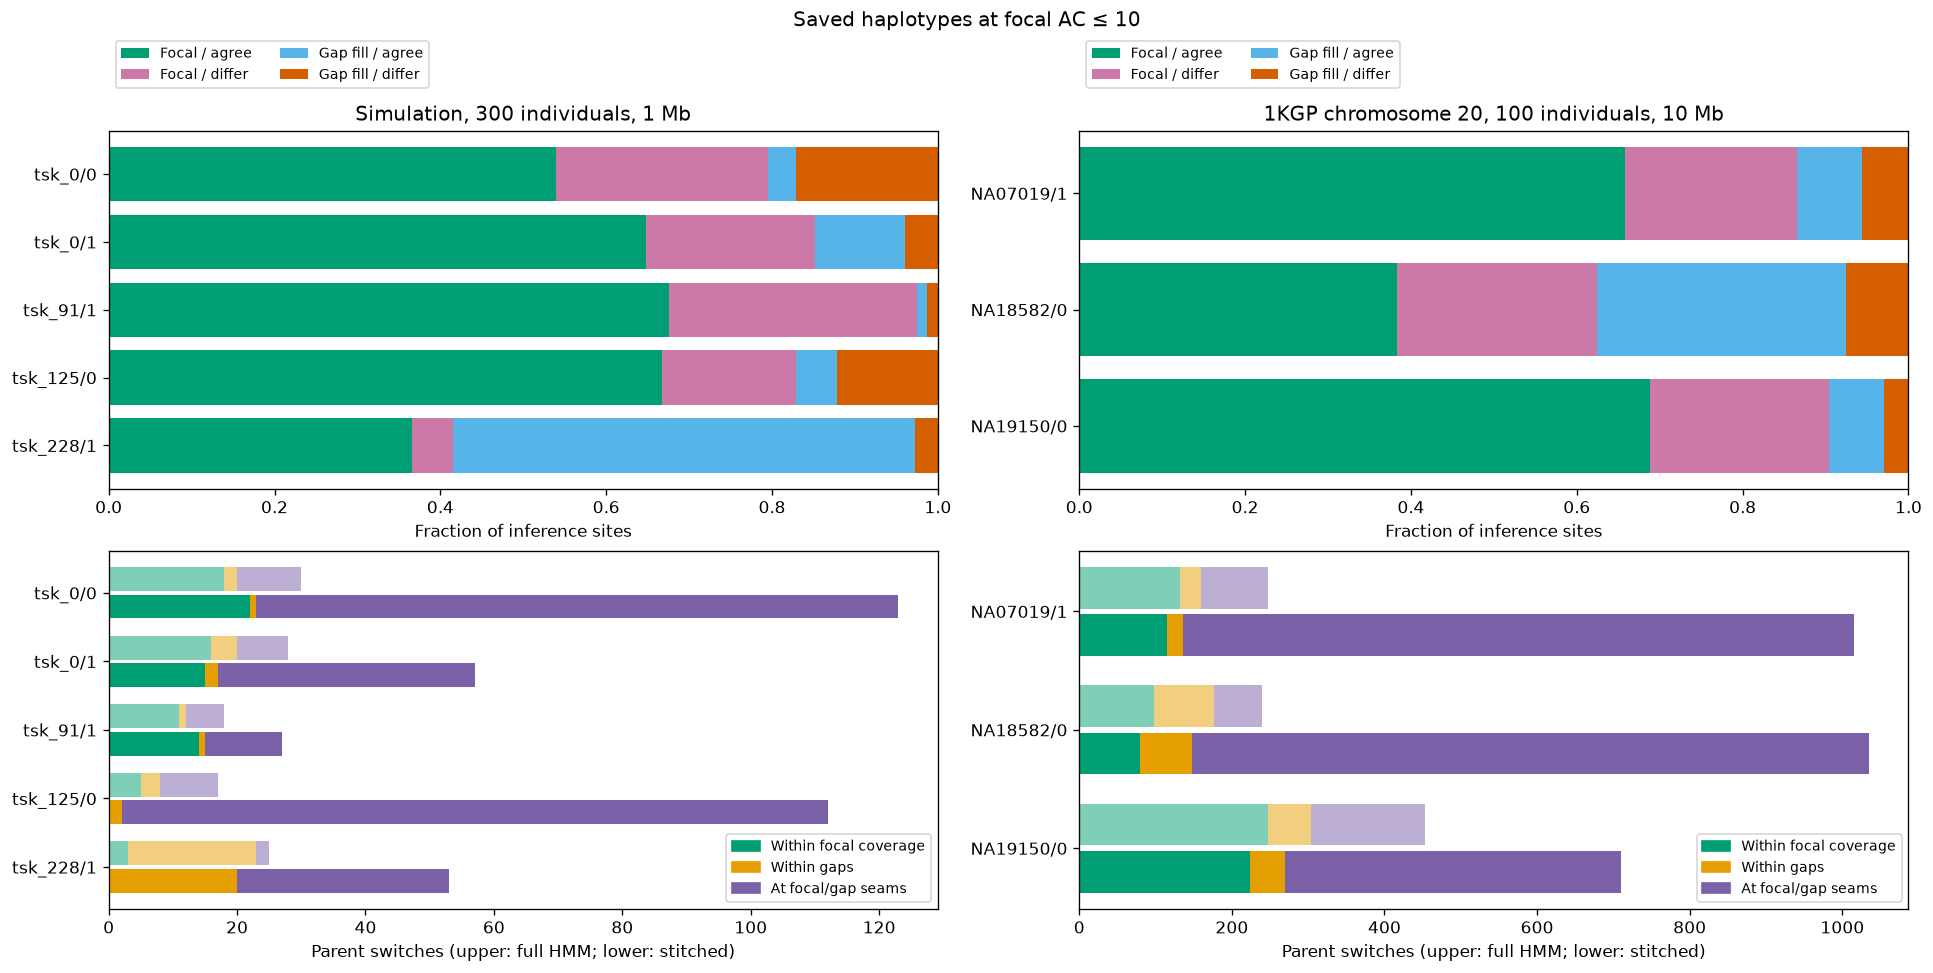

,dataset,haplotype,method,Within focal coverage,Within gaps,At focal/gap seams
0,"Simulation, 300 individuals, 1 Mb",tsk_0/0,full,18,2,10
1,"Simulation, 300 individuals, 1 Mb",tsk_0/1,full,16,4,8
2,"Simulation, 300 individuals, 1 Mb",tsk_91/1,full,11,1,6
3,"Simulation, 300 individuals, 1 Mb",tsk_125/0,full,5,3,9
4,"Simulation, 300 individuals, 1 Mb",tsk_228/1,full,3,20,2
5,"Simulation, 300 individuals, 1 Mb",tsk_0/0,stitched,22,1,100
6,"Simulation, 300 individuals, 1 Mb",tsk_0/1,stitched,15,2,40
7,"Simulation, 300 individuals, 1 Mb",tsk_91/1,stitched,14,1,12
8,"Simulation, 300 individuals, 1 Mb",tsk_125/0,stitched,0,2,110
9,"Simulation, 300 individuals, 1 Mb",tsk_228/1,stitched,0,20,33


In [4]:
coverage_agreement_and_switches_across_the_saved_haplotypes_result = (
    nb_plot.plot_coverage_agreement_and_switches_across_the_saved_haplotypes(
        datasets=datasets,
        experiment_config=experiment_config,
        figsize=[16, 8],
        xlim=(0, 1),
        xlabel="Fraction of inference sites",
        fontsize="small",
        height=0.35,
        xlabel_2="Parent switches (upper: full HMM; lower: stitched)",
    )
)
handles = coverage_agreement_and_switches_across_the_saved_haplotypes_result.handles
switch_rows = (
    coverage_agreement_and_switches_across_the_saved_haplotypes_result.switch_rows
)
switch_table = pd.DataFrame(switch_rows)
ipython_display.display(switch_table)

## Extra switch fraction

`num_extra_switches = stitched_switches - full_switches`, and
`extra_switch_fraction = num_extra_switches / stitched_switches`.
This reports the net extra switches as a proportion of all stitched switches,
using the stitched count as the denominator. It is undefined when the stitched
path has no switches, and can be negative if stitching reduces the count.
The count alone does not identify which individual switches are unnecessary.

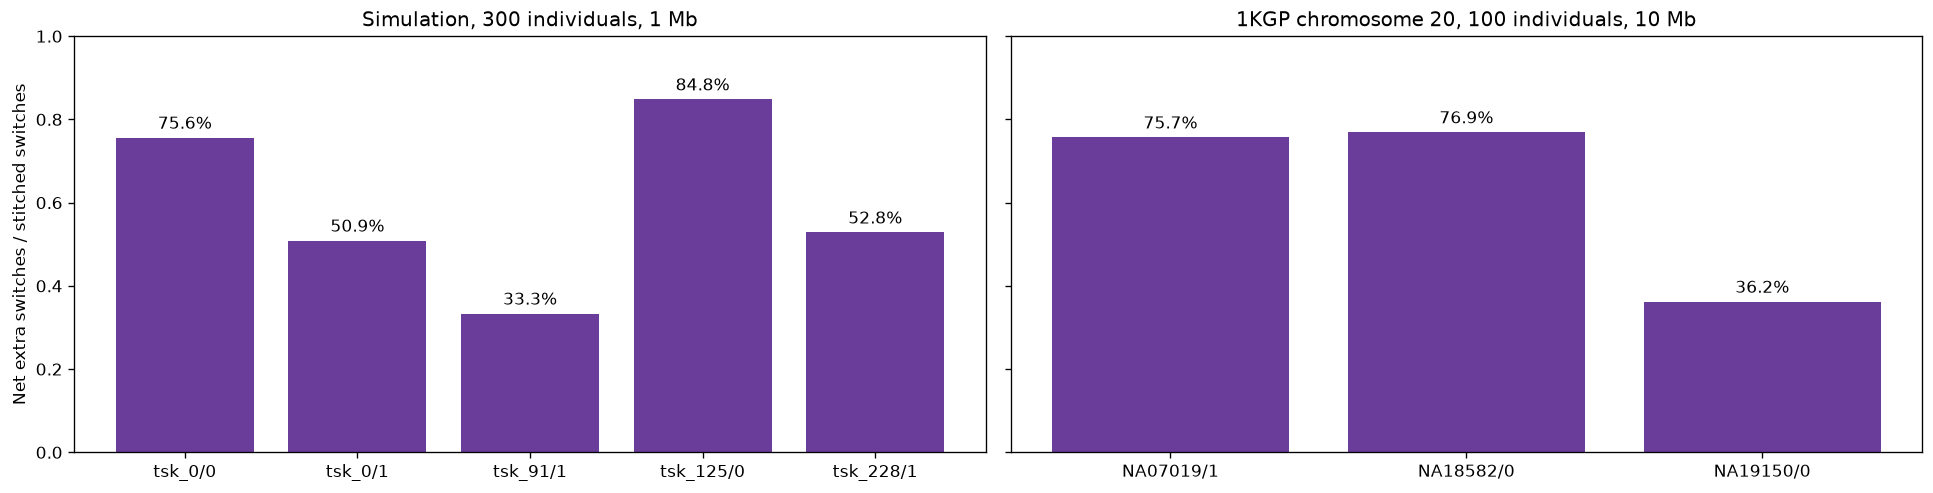

In [5]:
nb_plot.plot_extra_switch_fraction(
    datasets=datasets, figsize=[16, 4], color="#6A3D9A", ylim=(0, 1)
)

## Where retained focal pieces and gap fills agree with the full path

Each haplotype has two tracks: provenance (retained focal or gap fill), then
the four-way agreement classification. Genomic widths are a display convention:
a site's classification extends to the next inference-site position, with one
configured plotting width at the final site. This is **not** evidence of exact
focal matching between sites or beyond ancestor support. All counts and rates
remain site-based. The chromosome's unobserved flanks are excluded from plots.

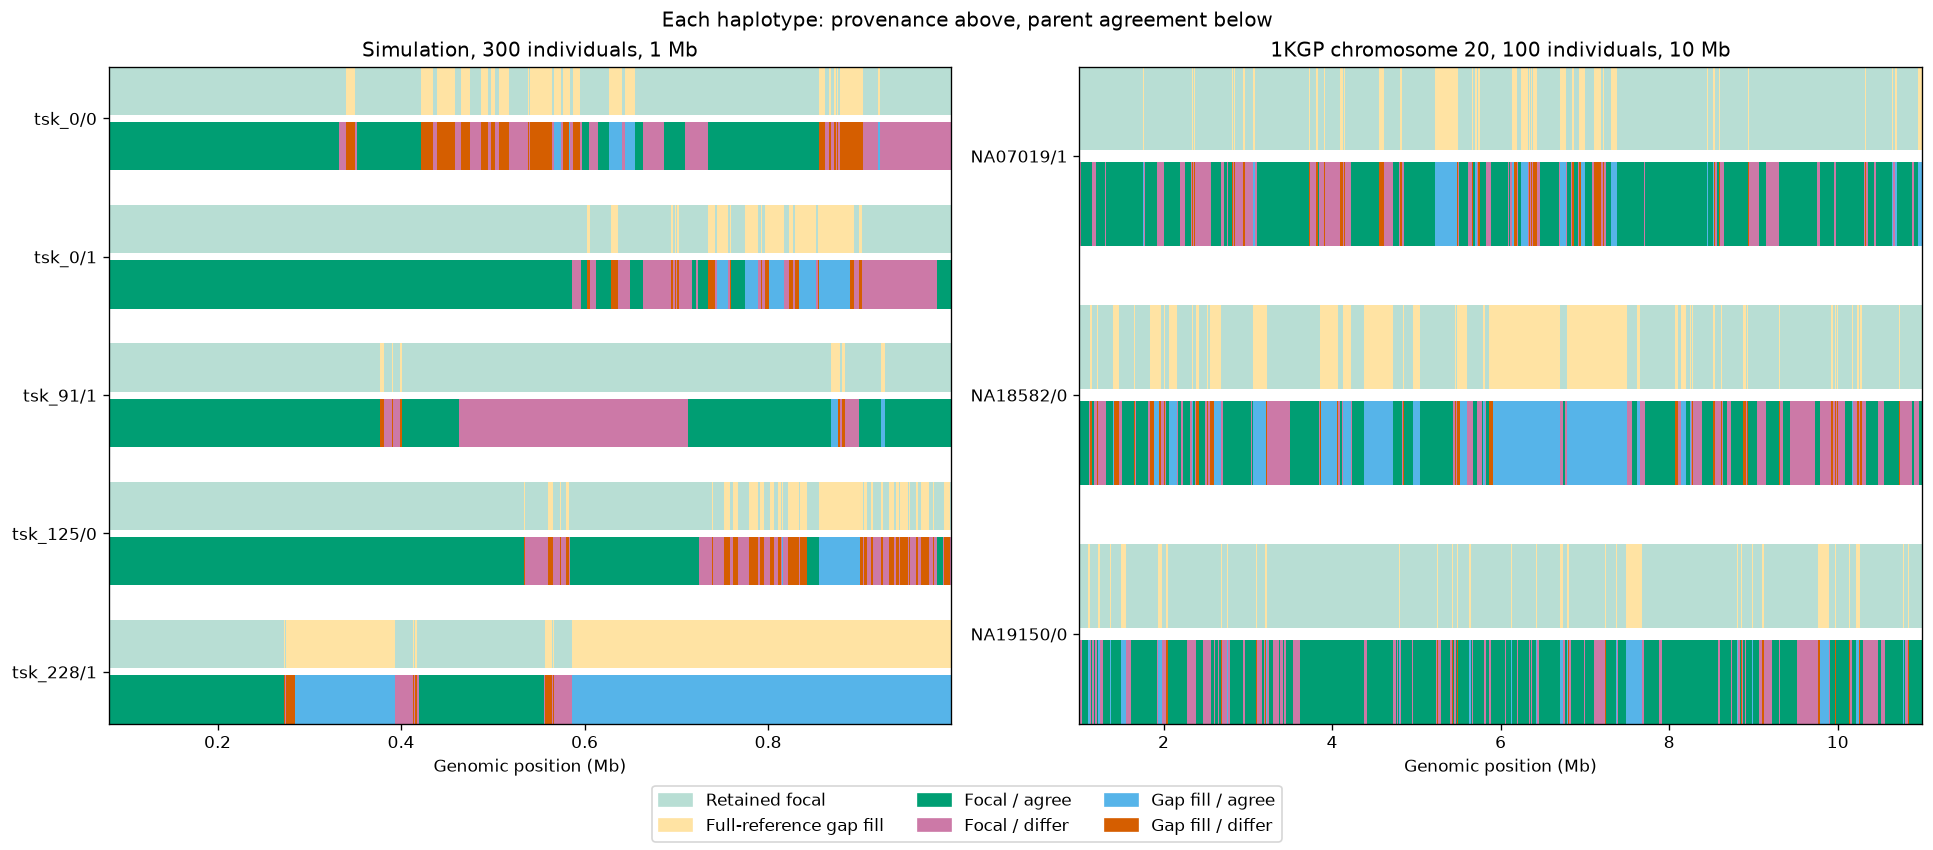

In [6]:
coverage_handles = (
    nb_plot.plot_where_retained_focal_pieces_and_gap_fills_agree_with_the_full(
        category_cmap=category_cmap,
        category_norm=category_norm,
        datasets=datasets,
        source_cmap=source_cmap,
        source_norm=source_norm,
        figsize=[16, 7],
    )
)

## Whole-span paths for the selected simulated and real haplotypes

The full HMM and stitched paths use the same original-node ID scale. Node IDs
identify parents; their vertical spacing has no biological distance meaning.
The source and agreement tracks show which parts were retained and which were
rematched. A gap's parent can agree with the full HMM for only part of that gap.

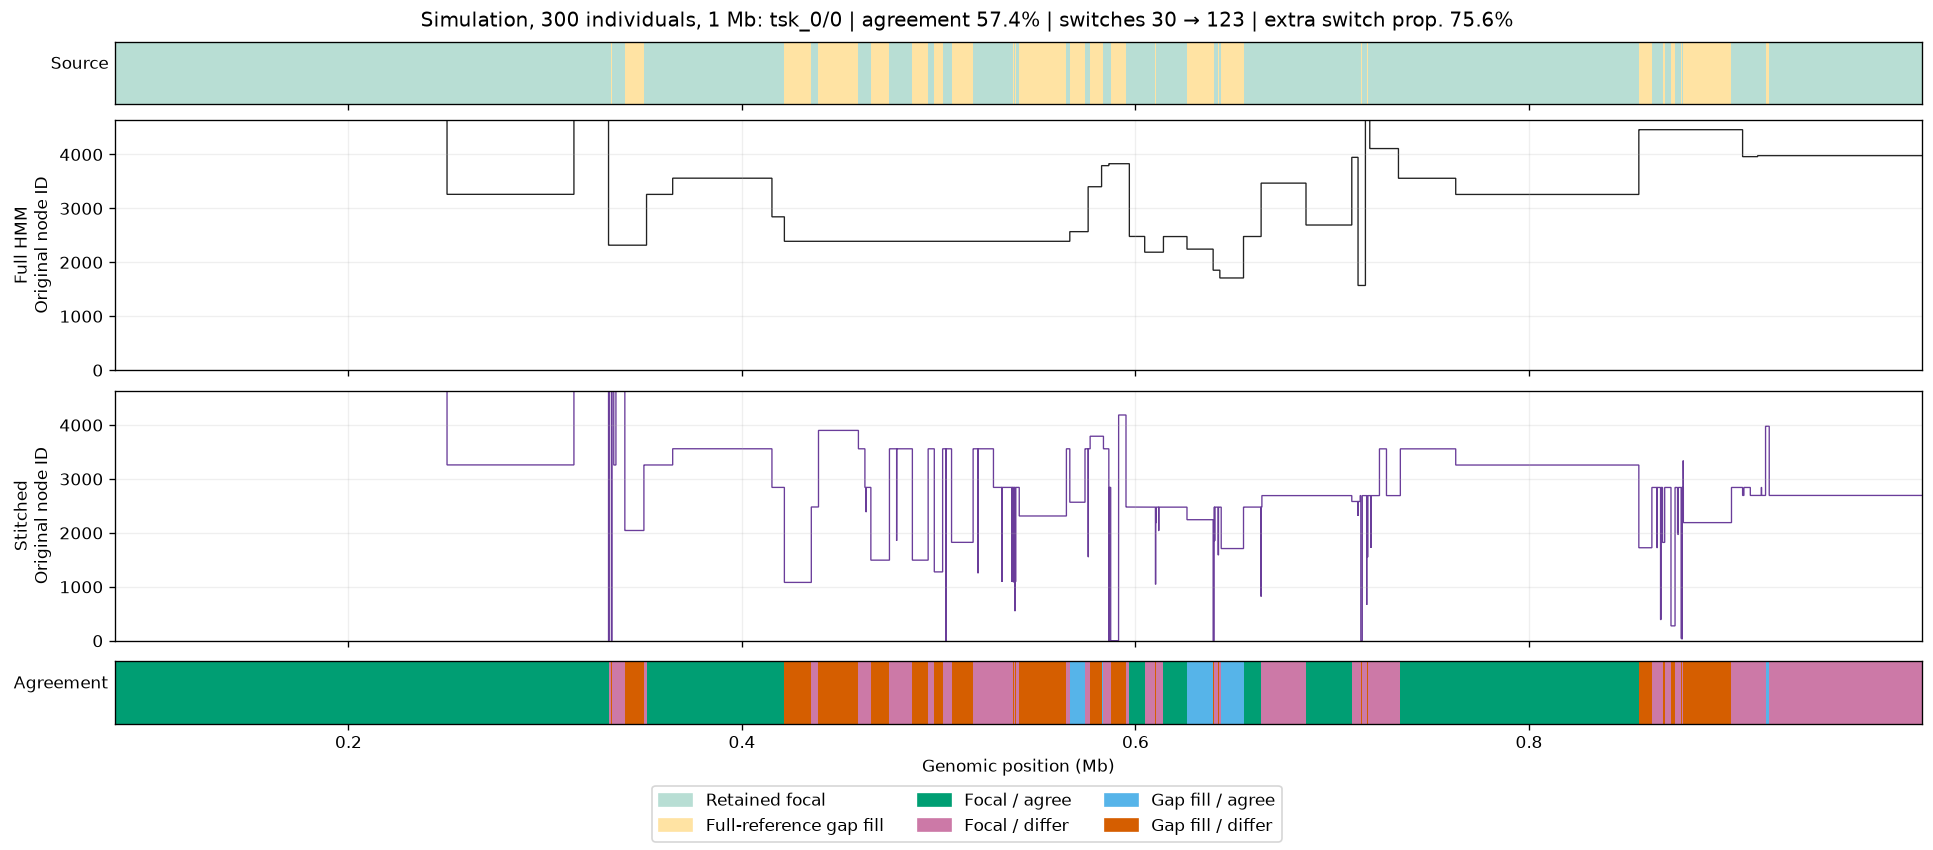

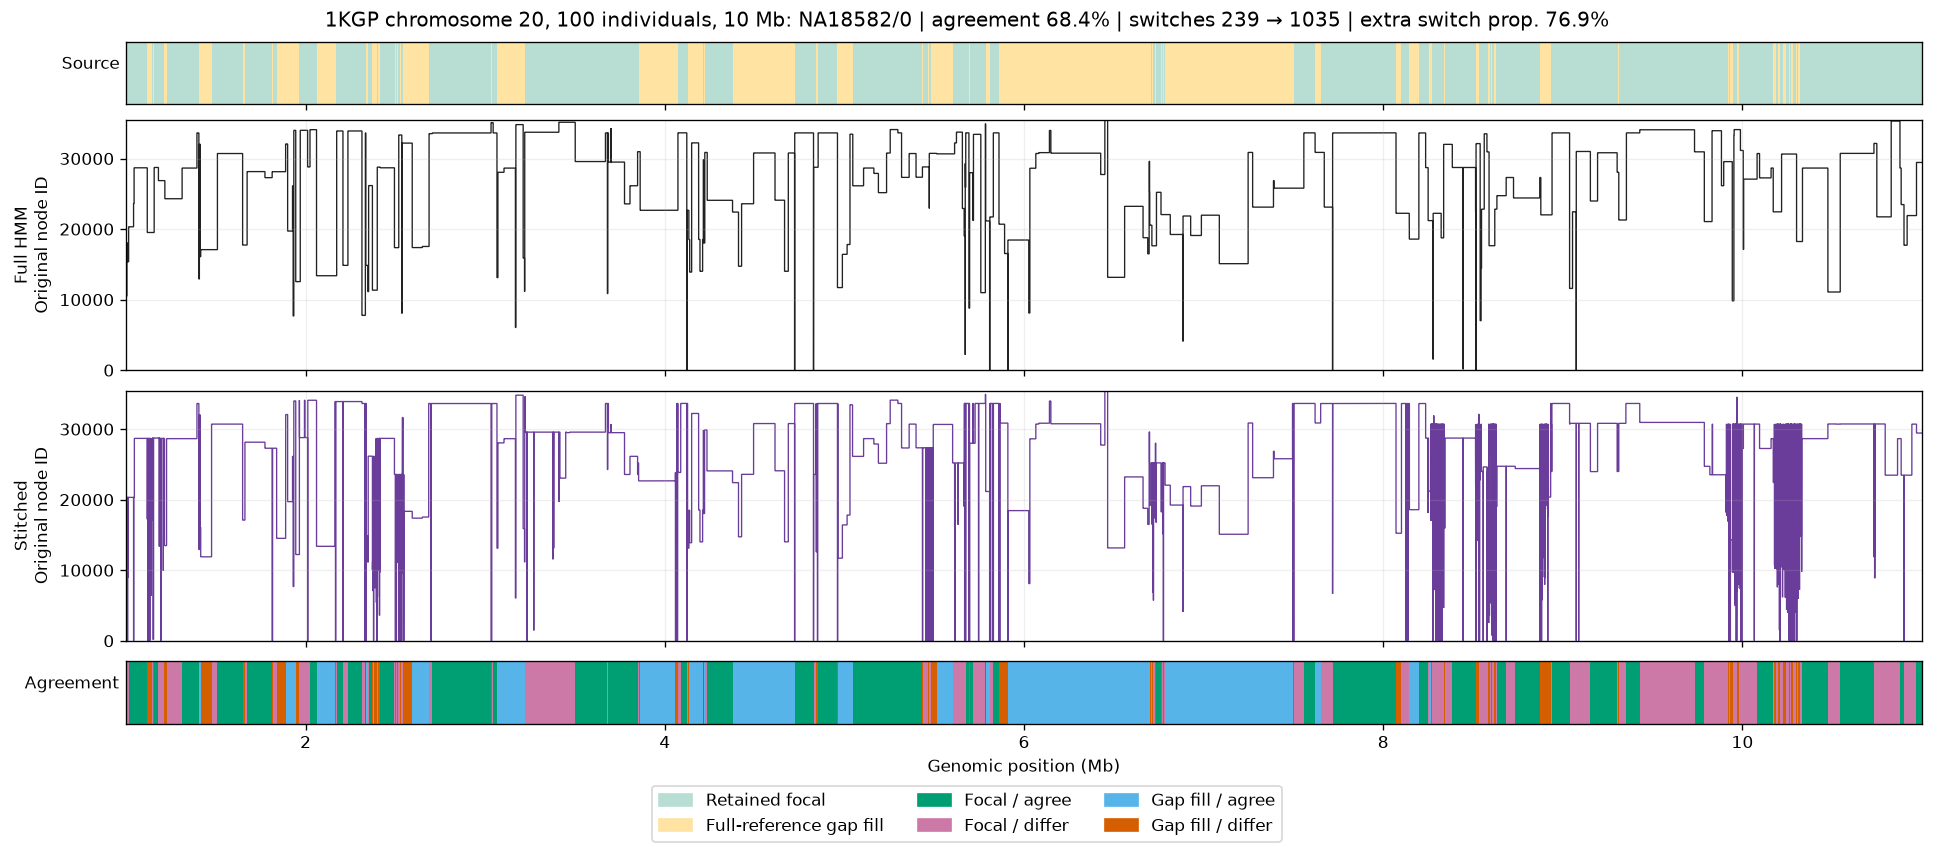

In [7]:
for dataset in datasets:
    nb_plot.plot_overview(
        dataset,
        category_cmap=category_cmap,
        category_norm=category_norm,
        coverage_handles=coverage_handles,
        plot_full_color="#222222",
        plot_genome_unit_bp=1000000,
        plot_genome_unit_label="Mb",
        plot_overview_figsize=[16, 7],
        plot_stitched_color="#6A3D9A",
        source_cmap=source_cmap,
        source_norm=source_norm,
    )

## Gap diagnostics and reproducible zoom selection

Each gap is summarized with its number of sites, agreement fraction, and the
switch counts strictly inside the gap. Left/right seam switches are reported
separately. Chromosome-edge gaps have no seam on their outer edge.

For each selected haplotype the notebook chooses four windows from the saved
site arrays, rather than hand-picking genomic coordinates:
- **Gap disagreement:** the gap with the most disagreeing sites; ties use NPZ
  interval order. The zoom is anchored on its first disagreeing site.
- **Gap agreement:** among gaps of at least the configured minimum size, choose
  the highest agreement fraction, breaking ties by longer gap then earlier
  interval. The zoom is anchored on its first agreeing site.
- **Mixed gap fill:** among gaps with both agreement and disagreement, choose
  the one with the most disagreeing sites, then the earliest gap. Anchor the
  zoom on its first within-gap transition between agreement and disagreement.
- **Focal disagreement:** the retained focal interval with the most disagreeing
  sites. The zoom is anchored on its first disagreement.

Short target intervals include their full extent and context on both sides.
Long intervals are clipped to the configured maximum site count around the
selected anchor, so a zoom may show only part of the target. Dashed lines mark
target boundaries when they are inside the displayed window. The table reports
both the complete target and the displayed half-open site window.

In [8]:
gap_tables = {}
detail_windows = {}
for dataset in datasets:
    gaps = nb_utils.gap_diagnostics(dataset)
    gap_tables[dataset.name] = gaps
    detail_windows[dataset.name] = nb_utils.select_windows(dataset, gaps, config=config)
    print(f"{dataset.label}, {dataset.primary.label}: {len(gaps)} gaps")
    ipython_display.display(
        gaps.sort_values("differ_sites", ascending=False).head(10).round(4)
    )
    window_rows = []
    for window in detail_windows[dataset.name]:
        target_disagreement = dataset.primary.disagreement[
            window.target_start : window.target_end
        ]
        window_rows.append(
            {
                **dataclasses.asdict(window),
                "target_agree_sites": int(np.count_nonzero(~target_disagreement)),
                "target_differ_sites": int(np.count_nonzero(target_disagreement)),
                "display_start_bp": dataset.positions[window.start],
                "display_end_bp": dataset.site_edges[window.end],
            }
        )
    ipython_display.display(pd.DataFrame(window_rows))

Simulation, 300 individuals, 1 Mb, tsk_0/0: 50 gaps


,gap,start_site,end_site,num_sites,start_bp,end_bp,agree_sites,differ_sites,agreement_fraction,full_interior_switches,full_left_seam_switch,full_right_seam_switch,stitched_interior_switches,stitched_left_seam_switch,stitched_right_seam_switch
18,18,3134,3306,172,540927.0,564894.0,0,172,0.0000,0,False,False,0,True,True
4,4,2444,2604,160,438894.0,459181.0,0,160,0.0000,0,False,False,0,True,True
48,48,5330,5485,155,878459.0,902919.0,0,155,0.0000,0,False,False,0,True,True
3,3,2300,2411,111,421553.0,435242.0,0,111,0.0000,0,True,False,0,True,True
2,2,1750,1815,65,340472.0,350161.0,0,65,0.0000,0,False,False,0,True,True
11,11,2885,2950,65,506521.0,517480.0,0,65,0.0000,0,False,False,0,True,True
6,6,2650,2706,56,465510.0,474956.0,0,56,0.0000,0,False,False,0,True,True
38,38,5163,5209,46,855830.0,862458.0,0,46,0.0000,0,True,False,0,True,True
8,8,2778,2816,38,486609.0,494623.0,0,38,0.0000,0,False,False,0,True,True
21,21,3388,3432,44,576953.0,583723.0,9,35,0.2045,1,False,False,0,True,True


,kind,target_start,target_end,start,end,target_agree_sites,target_differ_sites,display_start_bp,display_end_bp
0,Gap disagreement,3134,3306,3109,3331,0,172,537255.0,568682.0
1,Gap agreement,3812,3875,3787,3900,63,0,639918.0,658607.0
2,Mixed gap fill,3388,3432,3363,3457,9,35,572860.0,588204.0
3,Focal disagreement,5624,6120,5599,5839,0,496,918252.0,957964.0


1KGP chromosome 20, 100 individuals, 10 Mb, NA18582/0: 444 gaps


,gap,start_site,end_site,num_sites,start_bp,end_bp,agree_sites,differ_sites,agreement_fraction,full_interior_switches,full_left_seam_switch,full_right_seam_switch,stitched_interior_switches,stitched_left_seam_switch,stitched_right_seam_switch
34,34,4565,5483,918,1838657.0,1965378.0,422,496,0.4597,6,False,False,6,True,True
174,174,31009,36517,5508,5866979.0,6707707.0,5047,461,0.9163,18,False,False,17,True,True
84,84,9164,10281,1117,2546249.0,2685310.0,743,374,0.6652,2,False,False,2,True,True
31,31,2276,2678,402,1405691.0,1476370.0,93,309,0.2313,3,True,False,3,True,True
150,150,28416,29075,659,5494586.0,5602414.0,501,158,0.7602,1,False,False,0,True,True
199,199,44981,45124,143,8071136.0,8101494.0,0,143,0.0000,0,True,False,0,True,True
108,108,18953,19547,594,4126720.0,4215290.0,493,101,0.8300,7,False,True,7,True,True
30,30,1181,1270,89,1214034.0,1225814.0,0,89,0.0000,1,False,False,0,True,True
32,32,3564,3650,86,1649260.0,1662102.0,0,86,0.0000,0,True,False,0,True,True
49,49,8265,8345,80,2381383.0,2392339.0,0,80,0.0000,0,False,False,0,True,True


,kind,target_start,target_end,start,end,target_agree_sites,target_differ_sites,display_start_bp,display_end_bp
0,Gap disagreement,4565,5483,4540,4780,422,496,1835705.0,1875966.0
1,Gap agreement,36936,41540,36911,37151,4604,0,6779059.0,6817230.0
2,Mixed gap fill,4565,5483,4856,5096,422,496,1885412.0,1915243.0
3,Focal disagreement,52140,55610,52115,52355,735,2735,9305855.0,9349379.0


## Detailed parent paths: retained focal pieces, gap fills, agreement, and difference

These zooms put both paths on **categorical rows labeled by original ancestor
identity and node ID**. Rows are shared within each panel; matching parent IDs
occupy exactly the same row. Solid purple is stitched; dashed black is full HMM.
Markers locate inference sites. Background shading shows provenance, and the
lower agreement strip distinguishes all four source/agreement combinations.
The bottom rug marks full-path switches above and stitched-path switches below.

A retained focal piece is exact in observed alleles by construction. A different
parent there is a copying-path difference, not evidence of an allele mismatch.

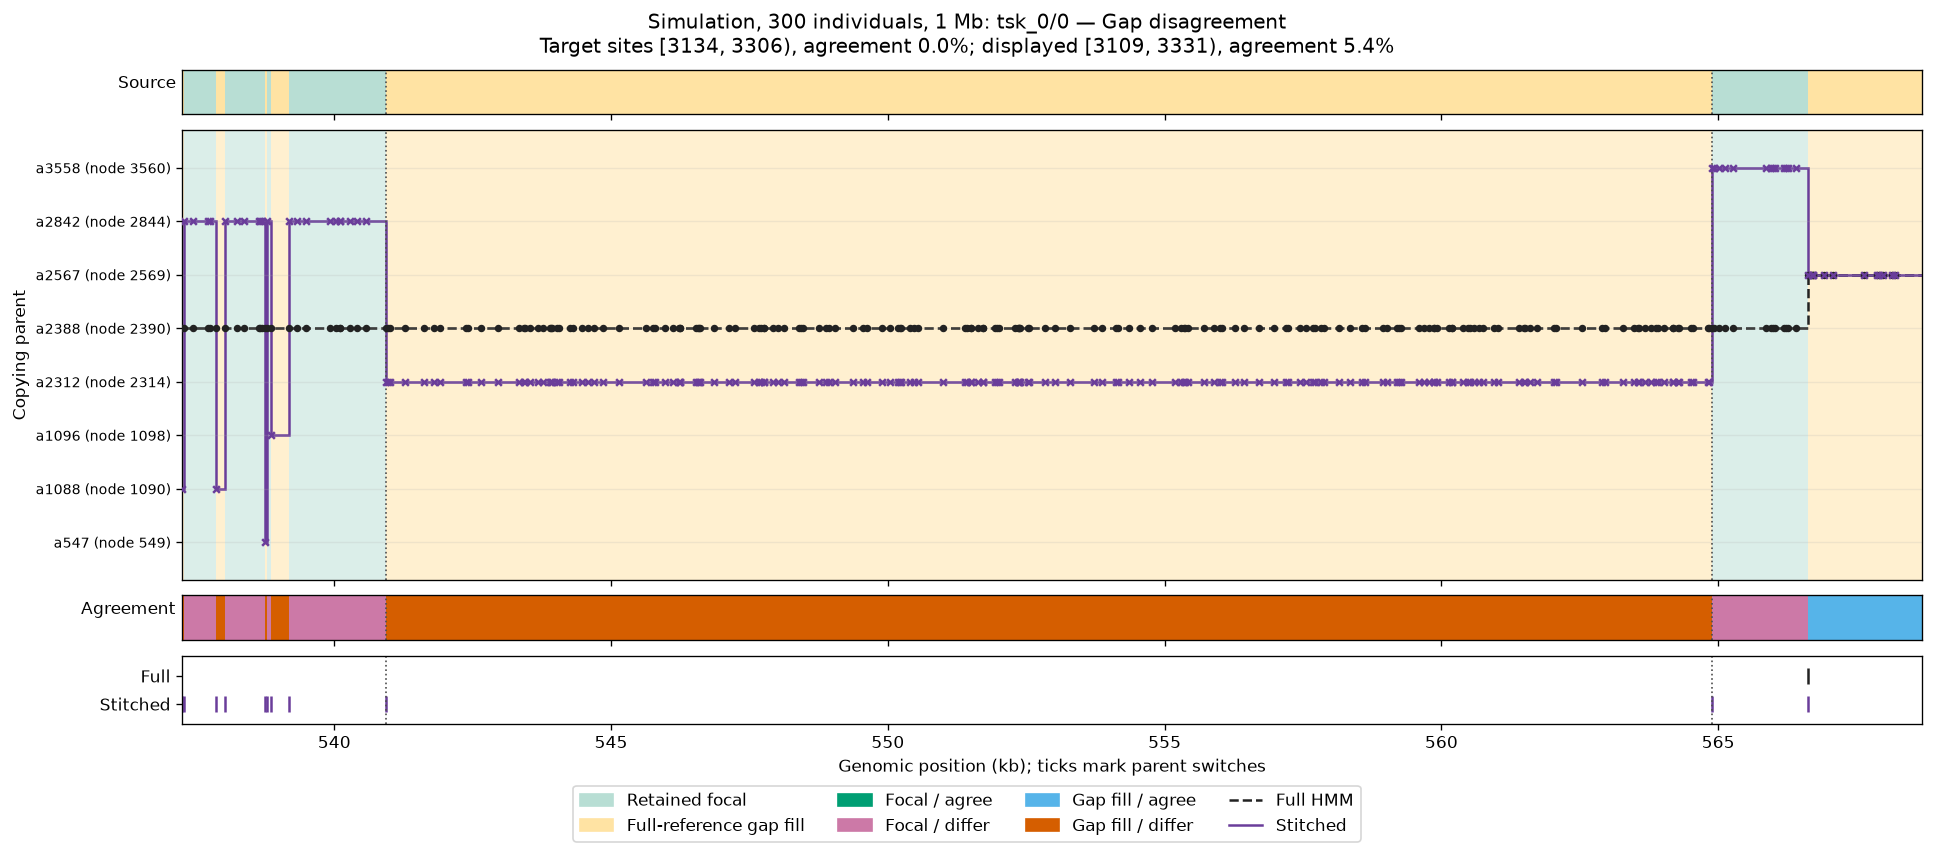

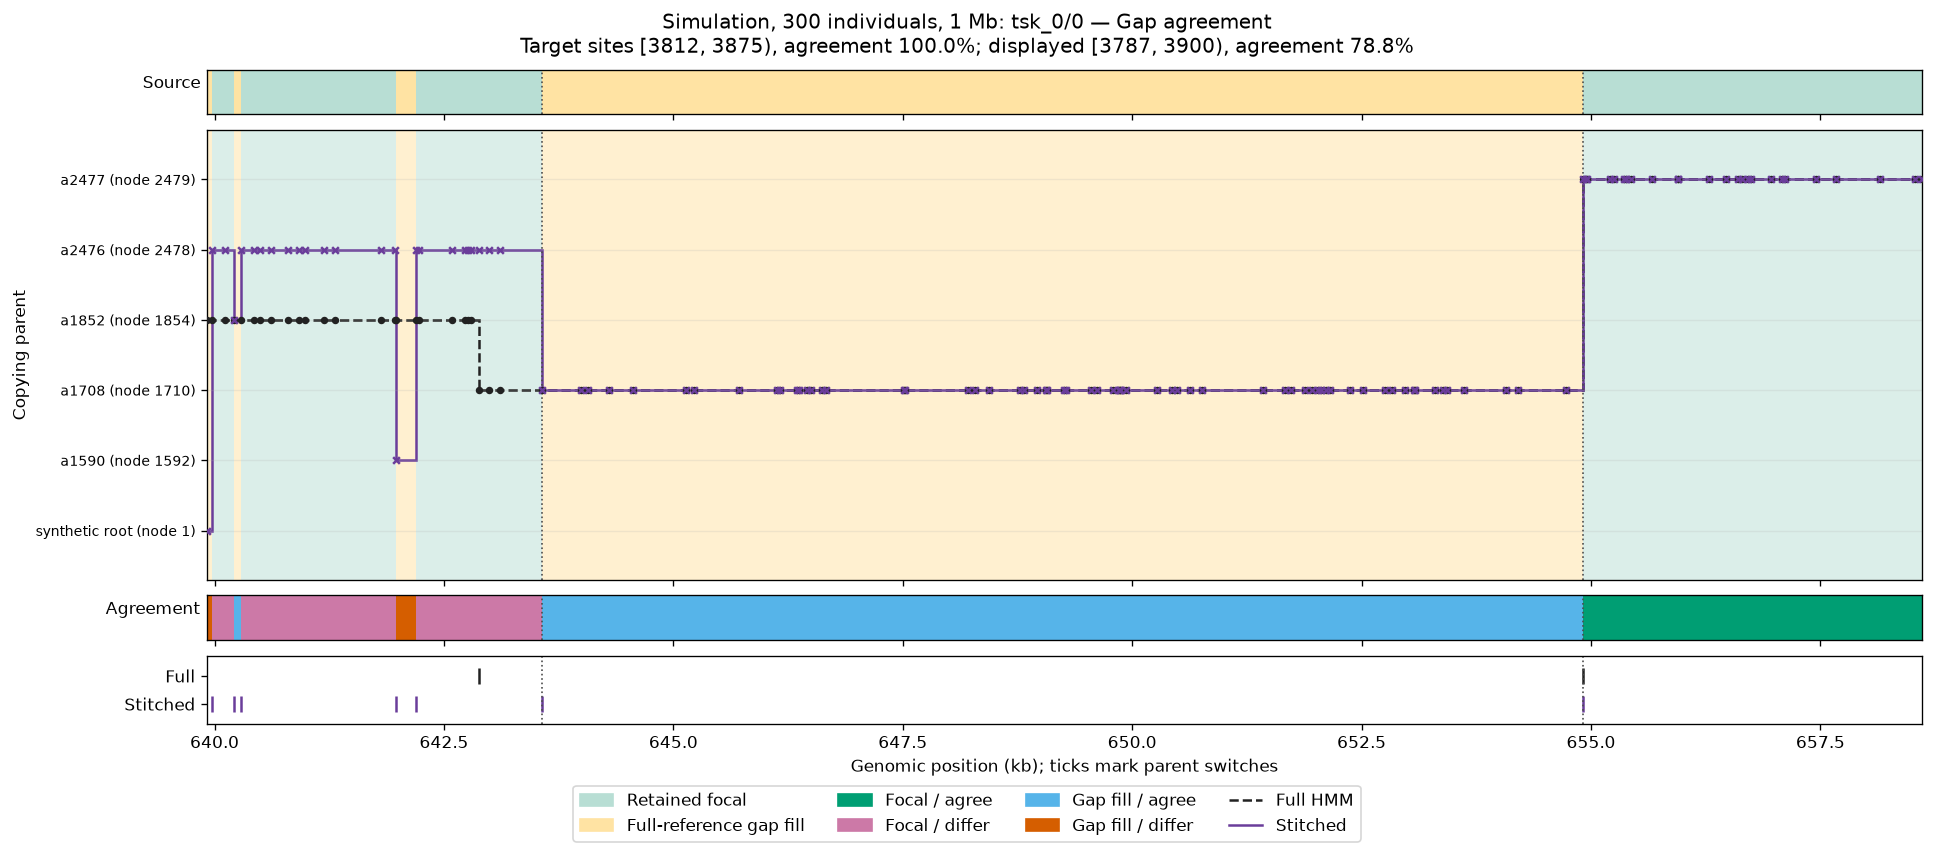

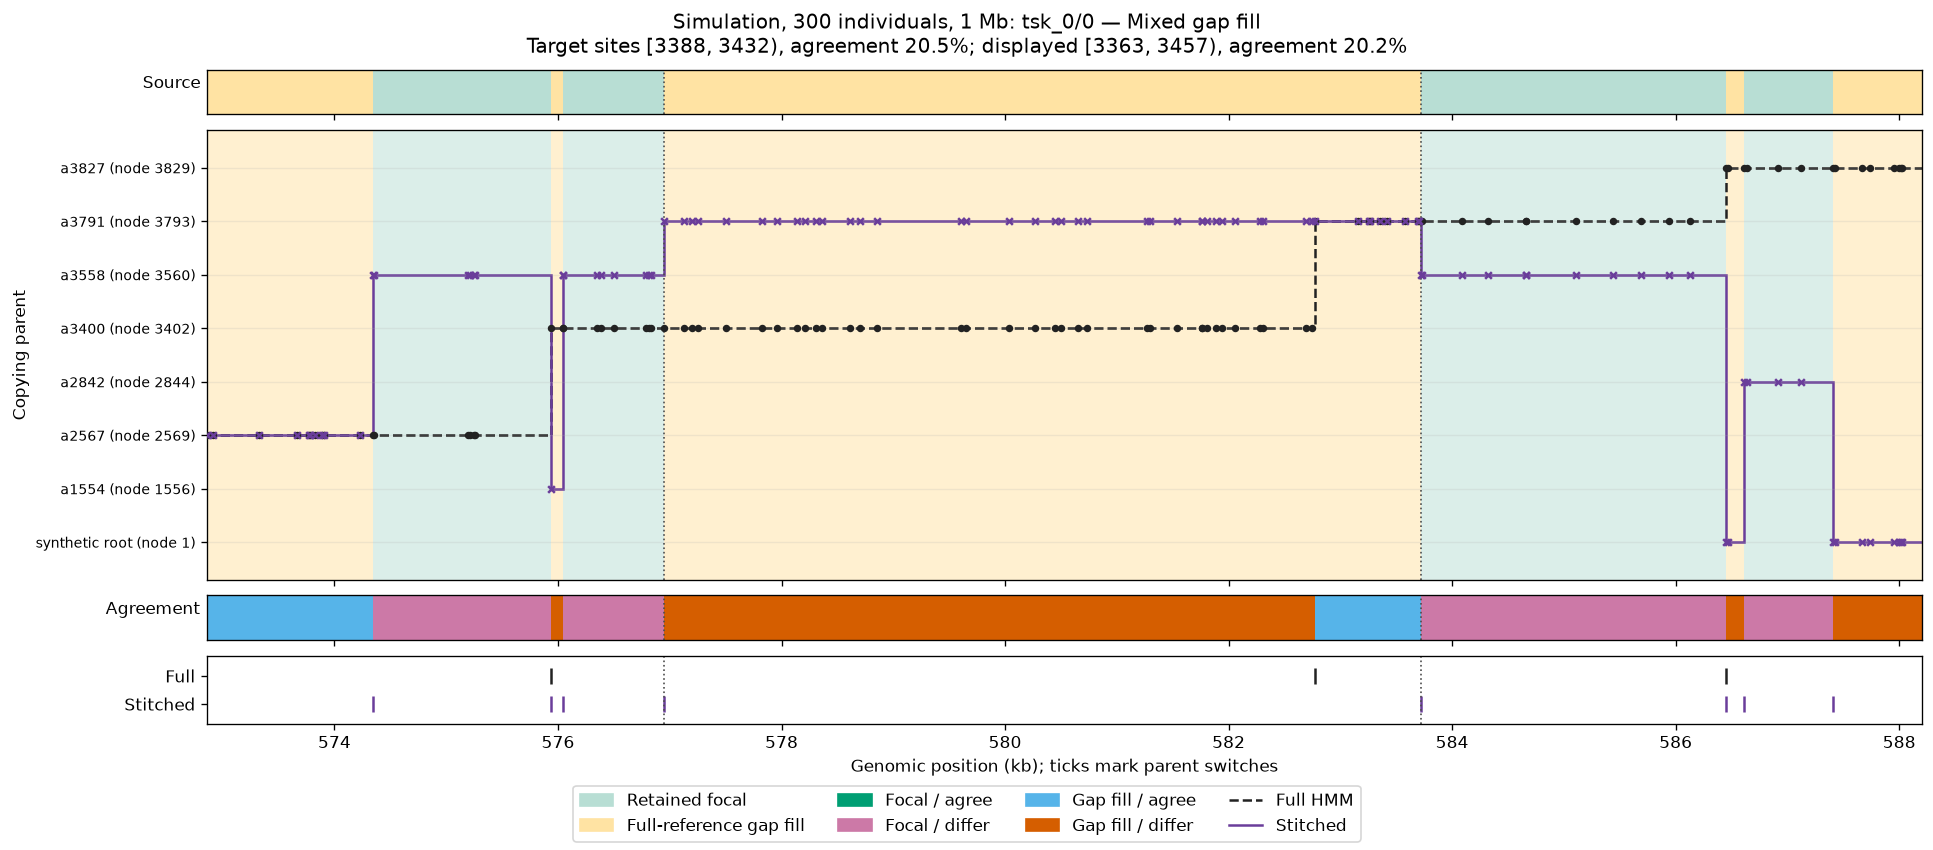

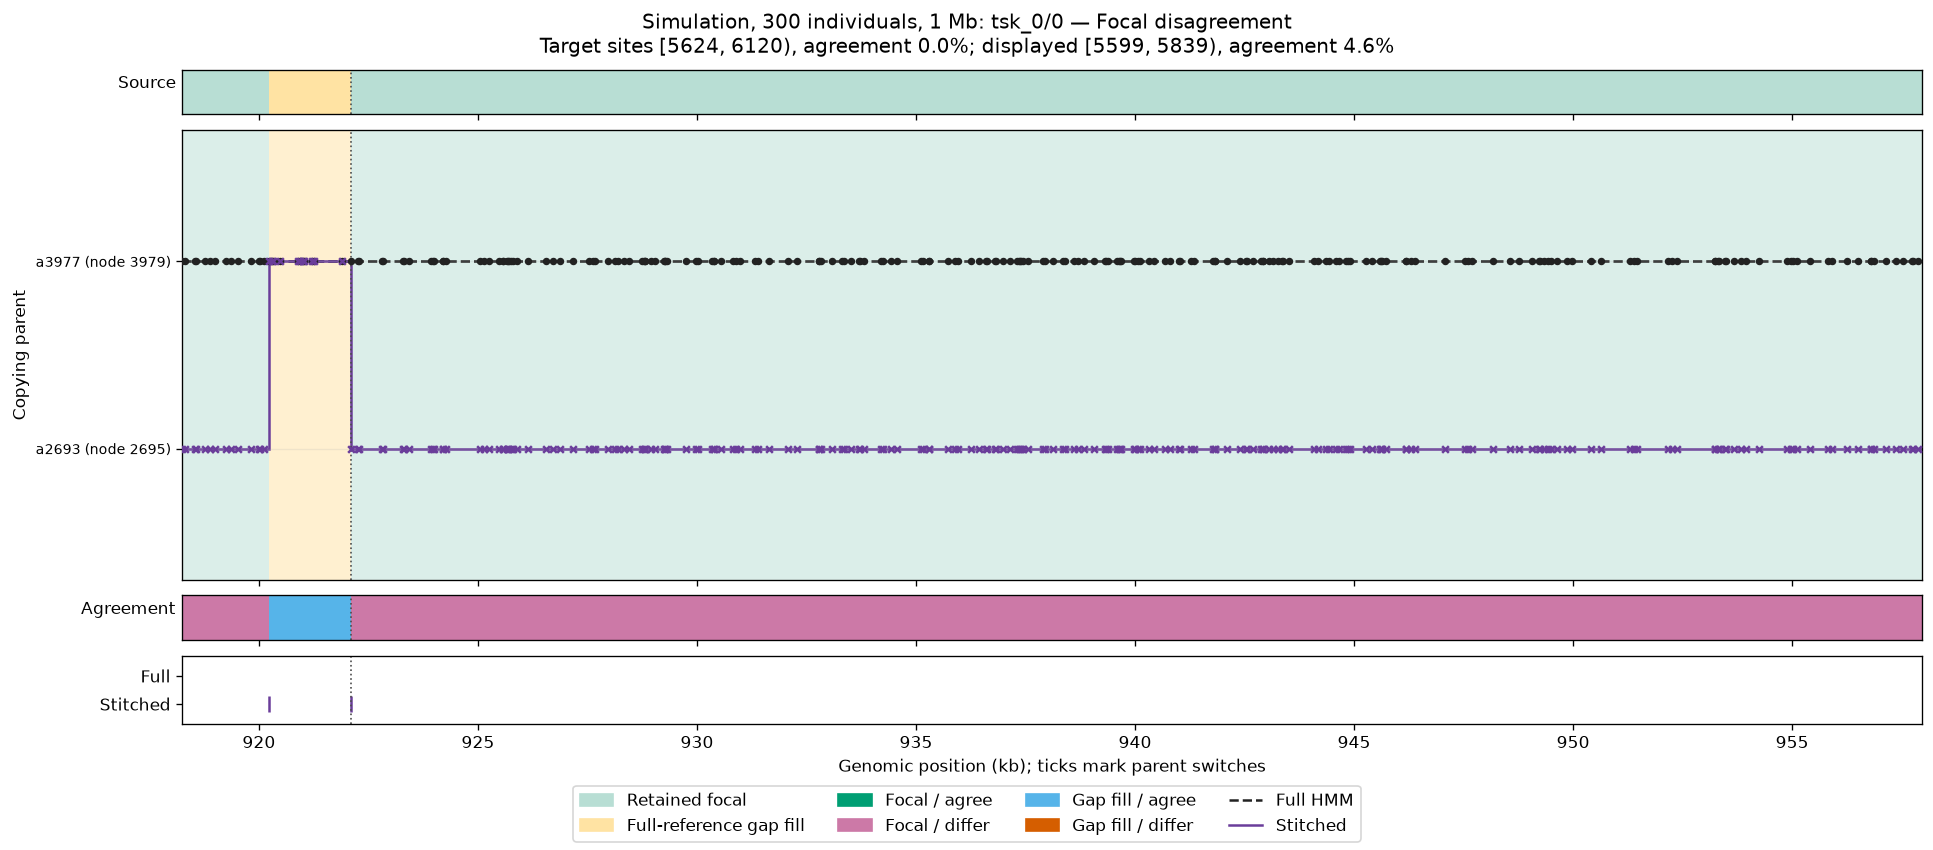

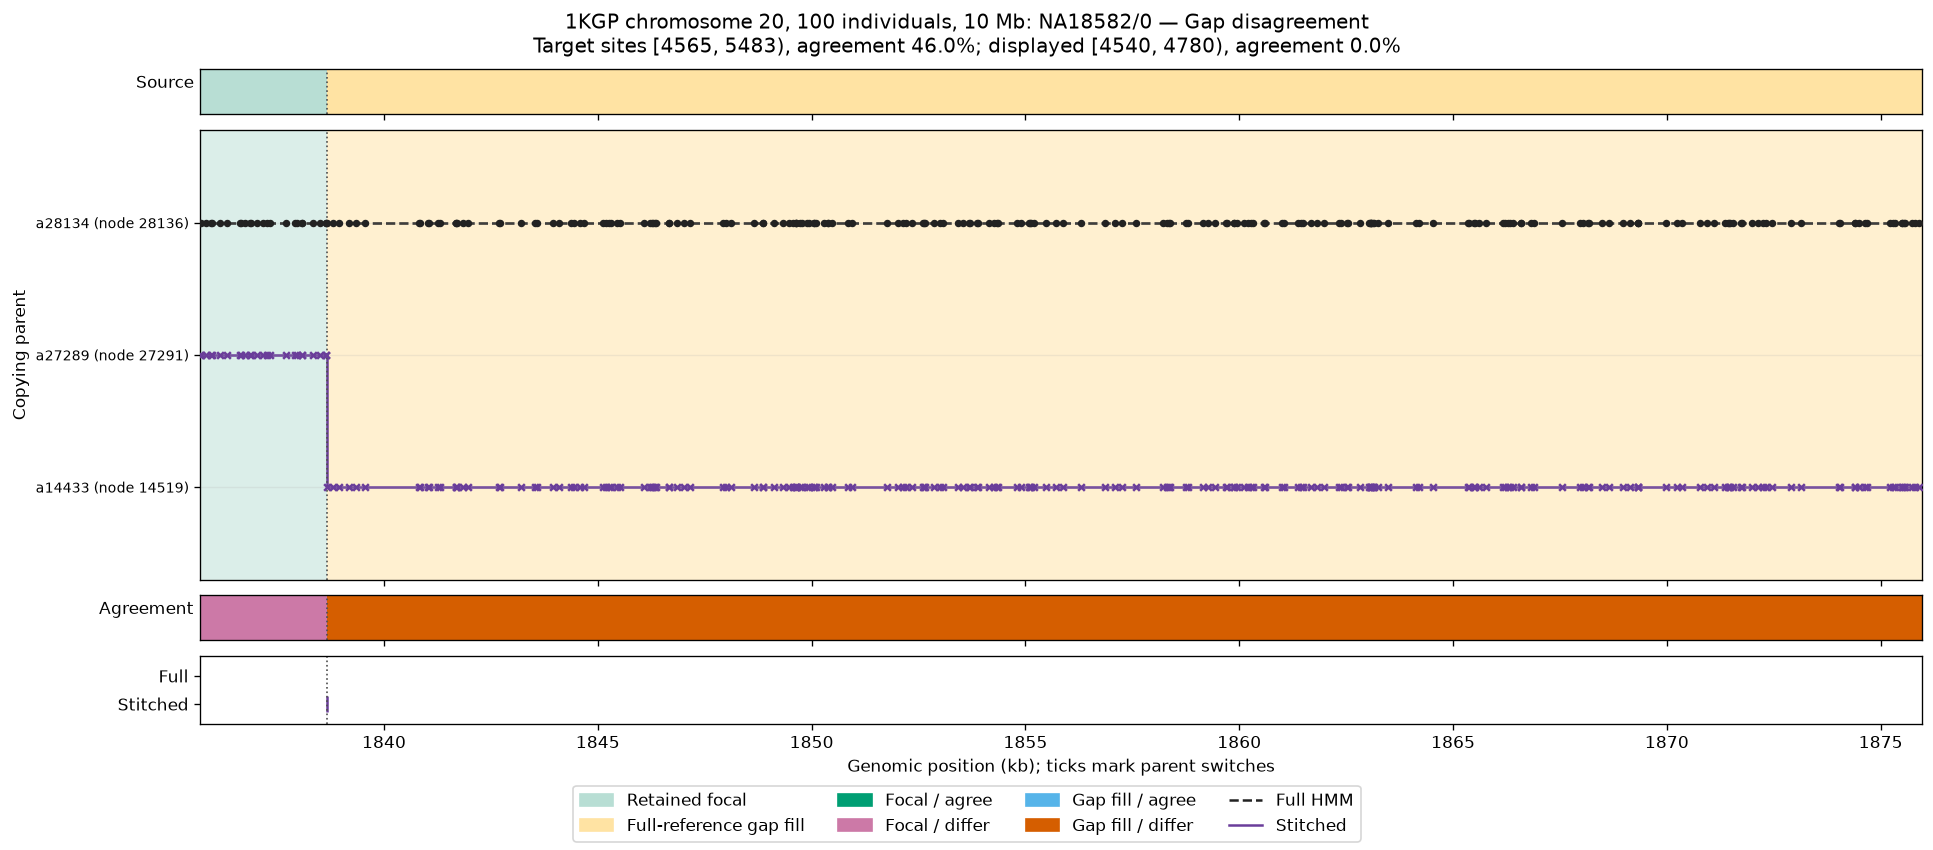

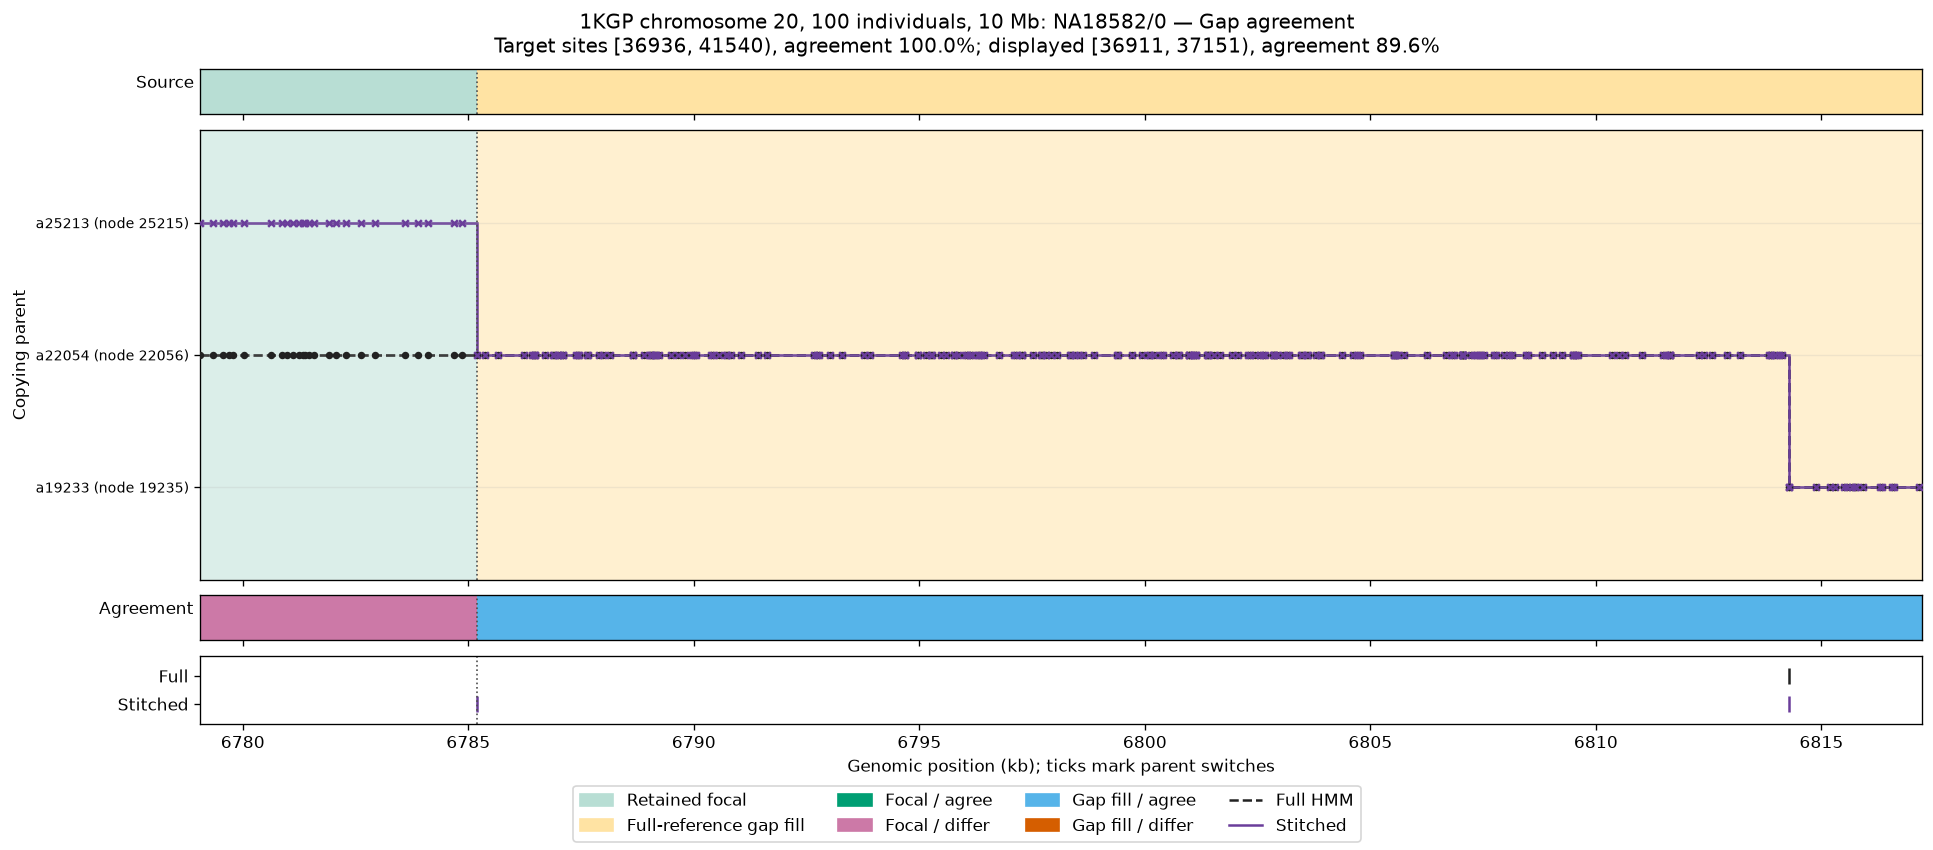

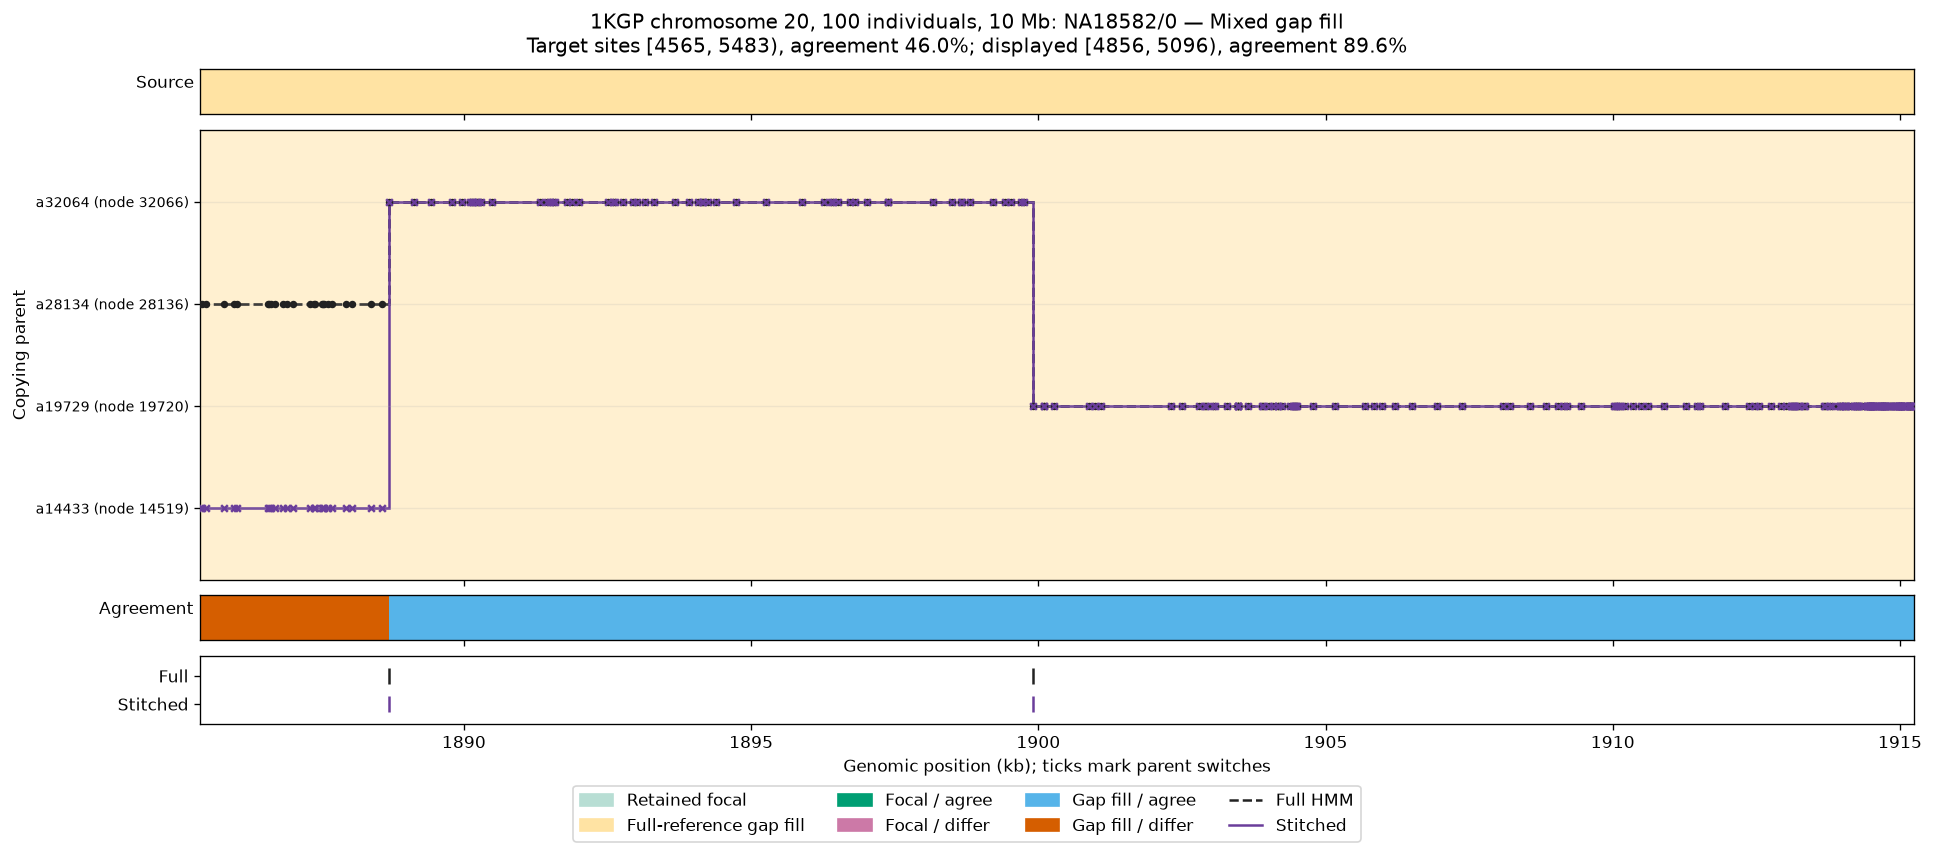

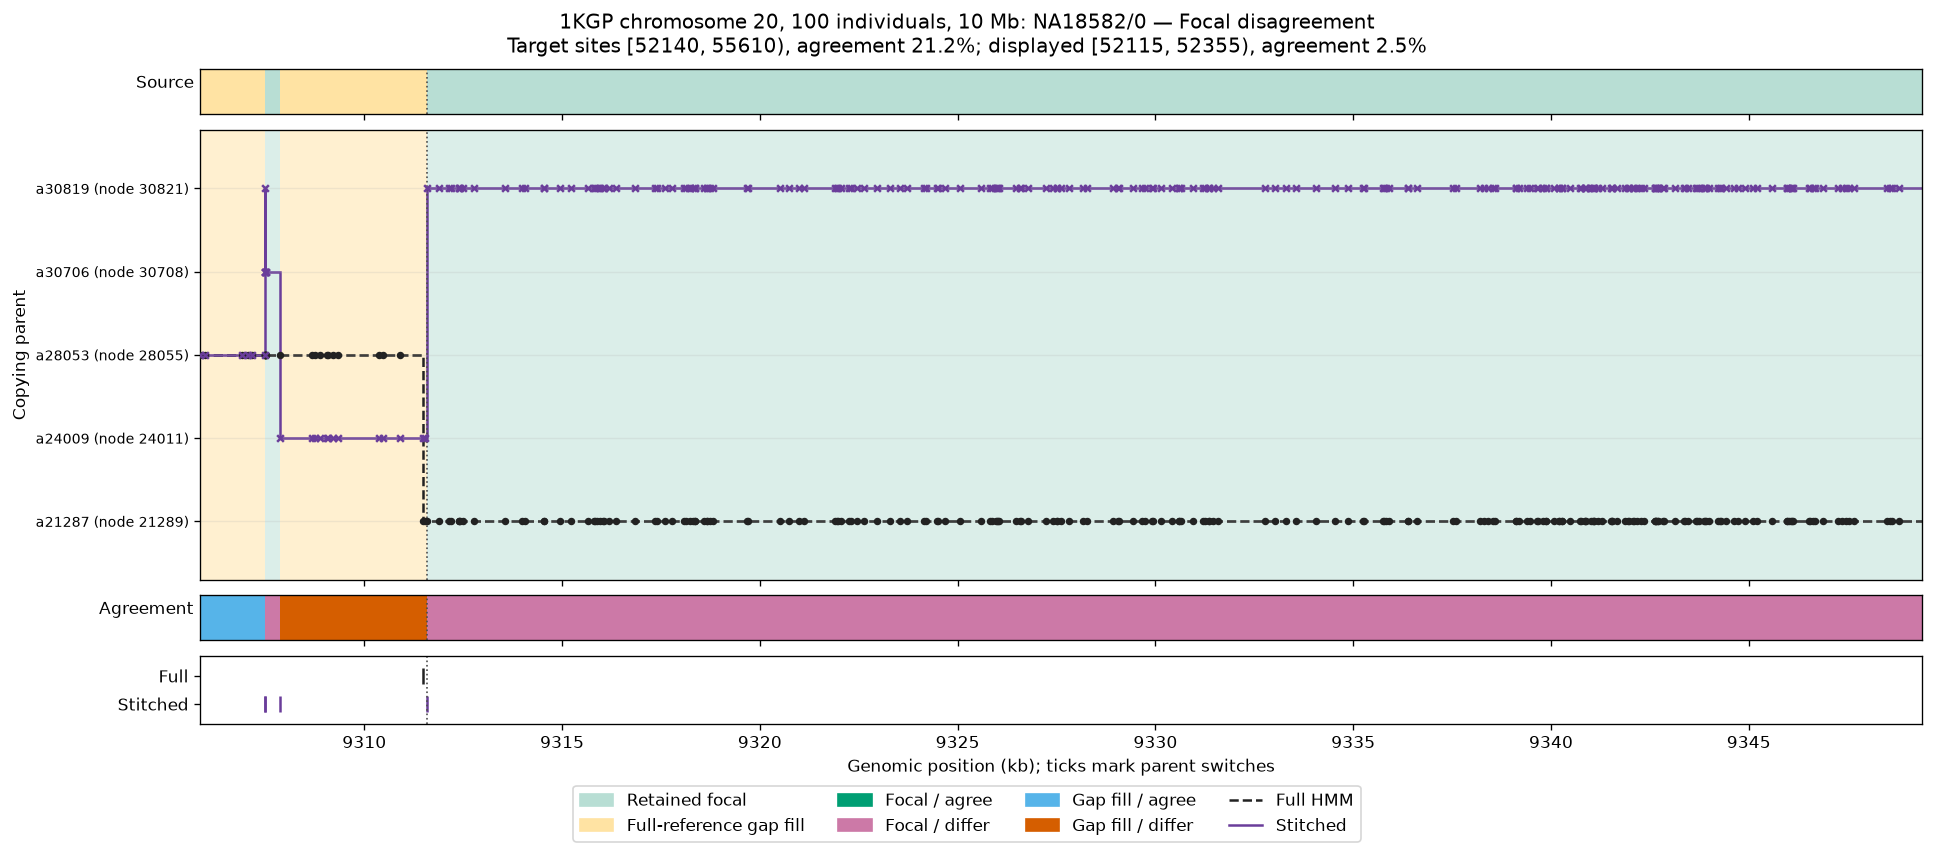

In [9]:
for dataset in datasets:
    for window in detail_windows[dataset.name]:
        nb_plot.plot_detail(
            dataset,
            window,
            category_cmap=category_cmap,
            category_norm=category_norm,
            coverage_handles=coverage_handles,
            plot_detail_figsize=[16, 7],
            plot_detail_unit_bp=1000,
            plot_detail_unit_label="kb",
            plot_full_color="#222222",
            plot_parent_row_height_in=0.24,
            plot_source_colors=["#B8DED4", "#FFE3A3"],
            plot_stitched_color="#6A3D9A",
            source_cmap=source_cmap,
            source_norm=source_norm,
        )

## Does disagreement concentrate near focal/gap seams?

Pool the saved haplotypes **within each dataset**, separating retained focal
sites from gap-fill sites. Distance is the number of inference-site steps to
the nearest provenance seam, with the immediately adjacent site on either side
assigned distance zero. Fractions use the actual site counts in each distance
bin; the accompanying table gives the denominators.

These are selected diagnostic haplotypes, not a representative population
sample. Proximity is descriptive and does not isolate a causal boundary effect.
In particular, distant disagreement within retained focal pieces means that
conditioning gap endpoints alone cannot recover this particular full parent path.

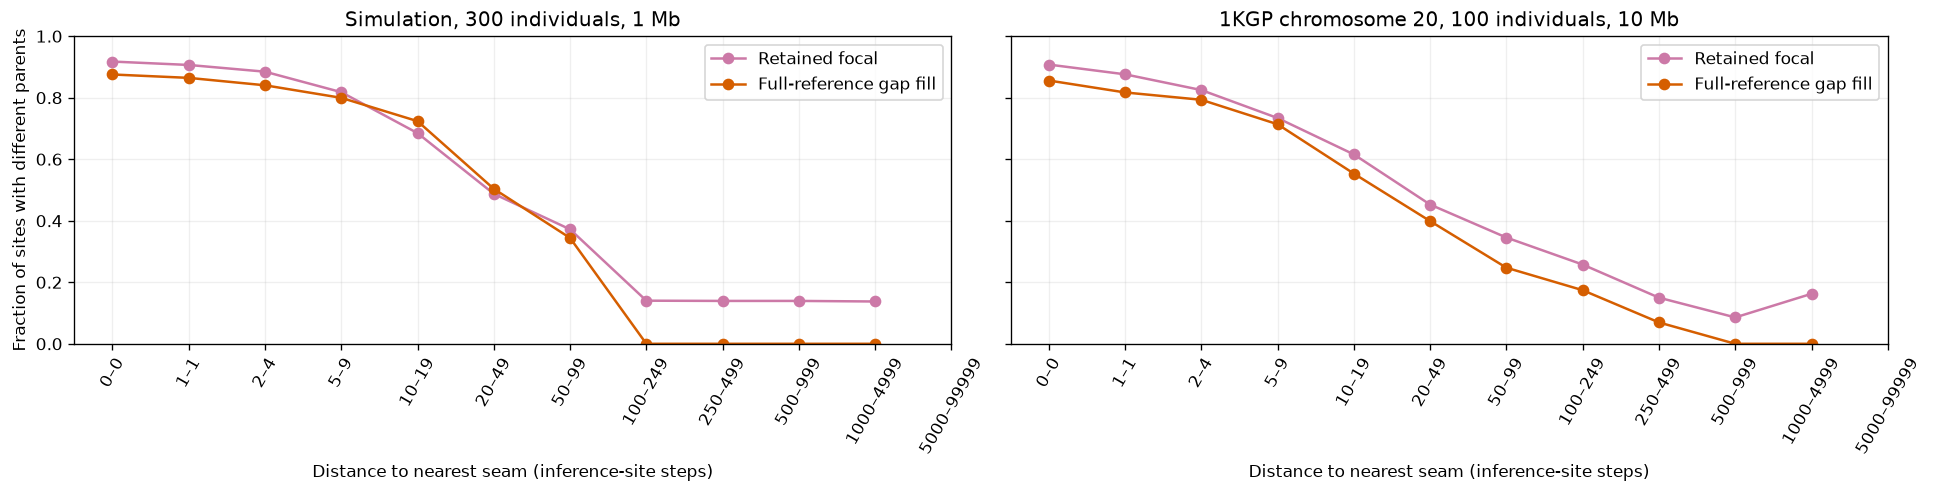

,dataset,source,distance_start,distance_end,num_sites,disagree_sites,disagreement_fraction
0,"Simulation, 300 individuals, 1 Mb",Retained focal,0,1,279,256,0.9176
1,"Simulation, 300 individuals, 1 Mb",Retained focal,1,2,246,223,0.9065
2,"Simulation, 300 individuals, 1 Mb",Retained focal,2,5,598,529,0.8846
3,"Simulation, 300 individuals, 1 Mb",Retained focal,5,10,654,535,0.8180
4,"Simulation, 300 individuals, 1 Mb",Retained focal,10,20,860,589,0.6849
5,"Simulation, 300 individuals, 1 Mb",Retained focal,20,50,1518,740,0.4875
6,"Simulation, 300 individuals, 1 Mb",Retained focal,50,100,1473,548,0.3720
7,"Simulation, 300 individuals, 1 Mb",Retained focal,100,250,3011,422,0.1402
8,"Simulation, 300 individuals, 1 Mb",Retained focal,250,500,3702,516,0.1394
9,"Simulation, 300 individuals, 1 Mb",Retained focal,500,1000,3587,500,0.1394


In [10]:
distance_rows = []
bins = np.array(config["distance_bin_edges"])
nb_plot.plot_does_disagreement_concentrate_near_focal_gap_seams(
    bins=bins,
    datasets=datasets,
    distance_rows=distance_rows,
    figsize=[16, 4],
    marker="o",
    ylim=(0, 1),
    xlabel="Distance to nearest seam (inference-site steps)",
    alpha=0.2,
)
distance_table = pd.DataFrame(distance_rows)
ipython_display.display(distance_table.loc[distance_table.num_sites > 0].round(4))

## Gap determination

The latest match-eval commit (`cbb7b57`) writes compact focal-ancestor **interval
NPZs**, replacing the old chunk CSV generation. The corresponding analysis
commit (`294486b`) sweeps those intervals for coverage. We use these new archives
and export coverage segments and both sets of gap bounds as CSVs below.
Older `*_focal_ancestor_chunks.csv` files are not inputs to this comparison.

The two definitions differ:
- **HMM-extracted gaps** are maximal runs not accepted from the reduced HMM
  path. Acceptance is checked independently at each site: the observed call
  must equal the copied allele, the parent must be an eligible focal candidate,
  and the site must lie inside that ancestor's support. A mismatch is rejected
  at that site, but the same parent can be accepted again beyond the mismatch.
  An accepted piece need not contain that ancestor's focal seed.
- **Zero-coverage gaps** are maximal runs outside the union of zero-mismatch
  intervals for all eligible ancestors. Each interval extends from the
  ancestor's **leftmost focal seed** and stops at the first mismatch or missing
  call in each direction, or at support/inference-interval bounds. It does not
  restart on a later exact island. This terminates the anchored extension;
  it does not globally remove the ancestor from all haplotypes.

Both methods use the same saved haplotypes, reference-site axis, and inclusive
upper AC cutoff. The coverage analysis also excludes AC=1, as its current
`summarise_coverage` implementation does. We check that no saved focal candidate
falls below that minimum here, so the eligibility sets agree for these runs.
Coverage uses generated ancestor calls; the HMM uses the inferred reference.
Their inferred/imputed alleles may also differ at missing ancestor calls.

Overlap is measured in **inference sites**. Report the intersection, each
method's exclusive sites, the fraction of each gap mask overlapped, and gap
intersection/union (IoU). Counts of maximal intervals are separate: fragmented
HMM gaps can overlap a much smaller number of long zero-coverage gaps. We also
count gaps with any overlap and exactly equal half-open bounds. No HMM path is
changed in this diagnostic comparison.

In [11]:
gap_comparisons = {
    dataset.name: nb_utils.compare_gap_determination(
        dataset,
        config=config,
        coverage_input_dir=coverage_input_dir,
        experiment_config=experiment_config,
        gap_comparison_dir=gap_comparison_dir,
        input_dir=input_dir,
    )
    for dataset in datasets
}
gap_summary = pd.DataFrame(
    [result.summary for results in gap_comparisons.values() for result in results]
)
ipython_display.display(gap_summary.round(4))

,dataset,source,sample_id,ploidy_index,ac_cutoff,max_mismatches,num_sites,num_coverage_intervals,hmm_num_gaps,zero_coverage_num_gaps,...,overlap_sites,hmm_only_gap_sites,zero_only_gap_sites,neither_gap_sites,gap_site_iou,hmm_gap_overlap_fraction,zero_coverage_gap_overlap_fraction,hmm_gaps_with_overlap,zero_coverage_gaps_with_overlap,exact_gap_bound_matches
0,out_of_africa_n300_1mbp,samples,tsk_0,0,10,0,6120,25,50,7,...,1218,33,840,4029,0.5825,0.9736,0.5918,50,7,1
1,out_of_africa_n300_1mbp,samples,tsk_0,1,10,0,6120,25,20,7,...,867,42,405,4806,0.6598,0.9538,0.6816,20,5,0
2,out_of_africa_n300_1mbp,samples,tsk_91,1,10,0,6120,41,6,2,...,102,54,139,5825,0.3458,0.6538,0.4232,5,2,0
3,out_of_africa_n300_1mbp,samples,tsk_125,0,10,0,6120,12,55,4,...,997,49,959,4115,0.4973,0.9532,0.5097,55,4,0
4,out_of_africa_n300_1mbp,samples,tsk_228,1,10,0,6120,2,17,2,...,3570,12,285,2253,0.9232,0.9966,0.9261,17,2,0
5,tgp_chr20_n100,samples,NA07019,1,10,0,61798,171,440,54,...,8063,247,10269,43219,0.4340,0.9703,0.4398,440,46,4
6,tgp_chr20_n100,samples,NA18582,0,10,0,61798,94,444,48,...,22809,409,10277,28303,0.6810,0.9824,0.6894,444,43,1
7,tgp_chr20_n100,samples,NA19150,0,10,0,61798,627,221,119,...,5388,559,5188,50663,0.4839,0.9060,0.5095,218,99,12


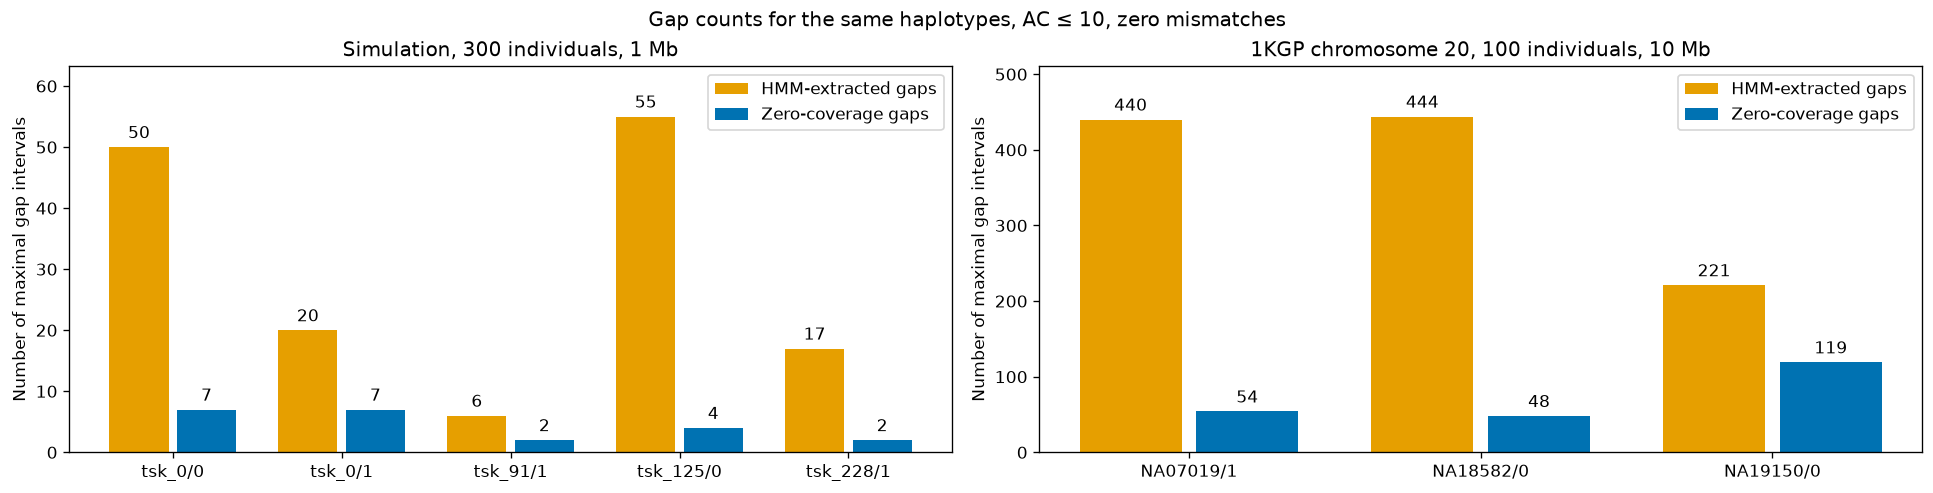

In [12]:
nb_plot.plot_gap_determination(
    datasets=datasets,
    experiment_config=experiment_config,
    gap_comparisons=gap_comparisons,
    figsize=(12, 4),
    width=0.35,
    ylabel="Number of maximal gap intervals",
)

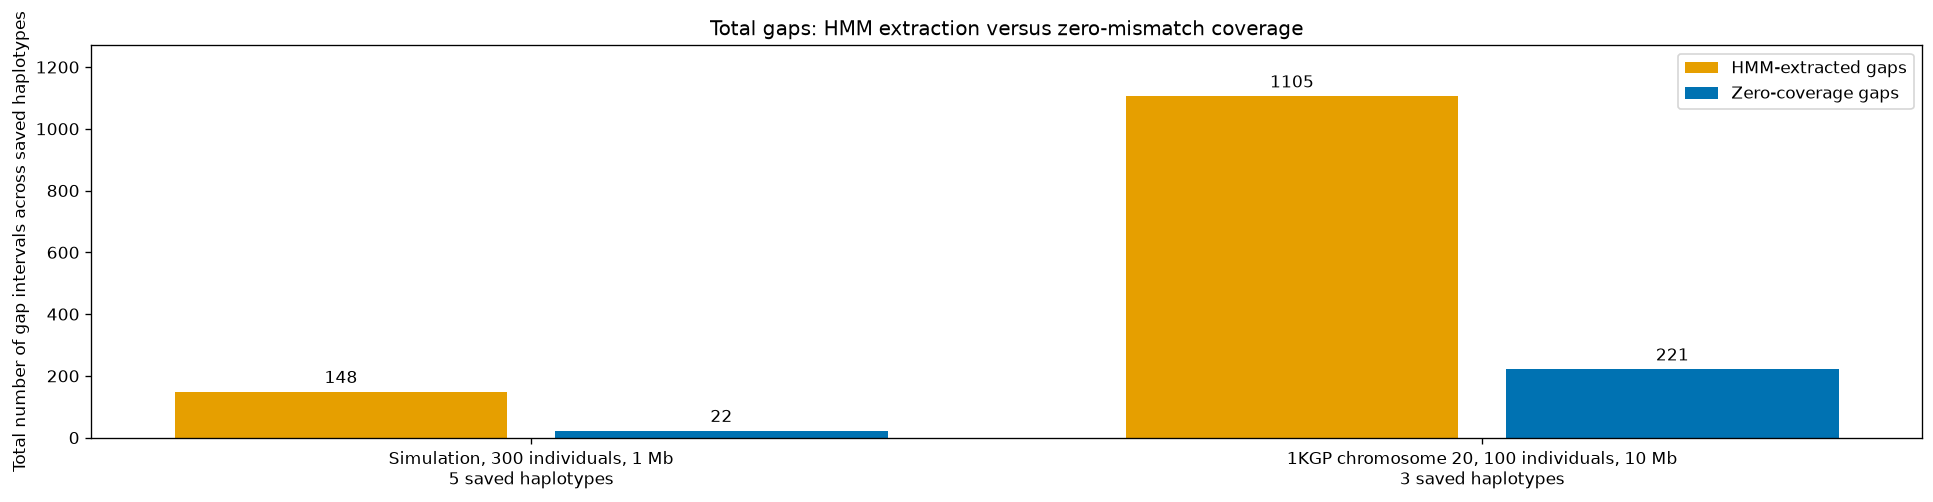

In [13]:
nb_plot.plot_gap_determination_2(
    datasets=datasets,
    gap_comparisons=gap_comparisons,
    figsize=(12, 4),
    width=0.35,
    ylabel="Total number of gap intervals across saved haplotypes",
    title="Total gaps: HMM extraction versus zero-mismatch coverage",
)

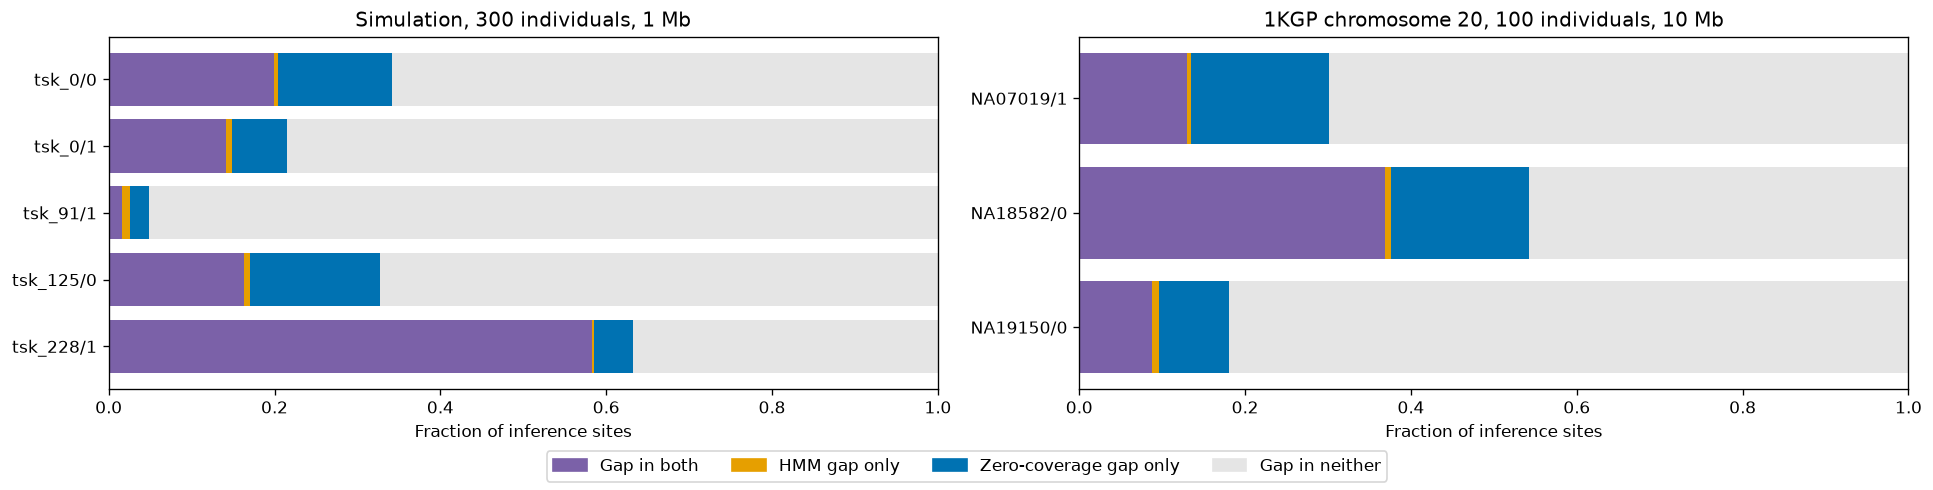

In [14]:
handles = nb_plot.plot_gap_determination_3(
    datasets=datasets,
    gap_comparisons=gap_comparisons,
    figsize=(12, 5),
    xlim=(0, 1),
    xlabel="Fraction of inference sites",
)

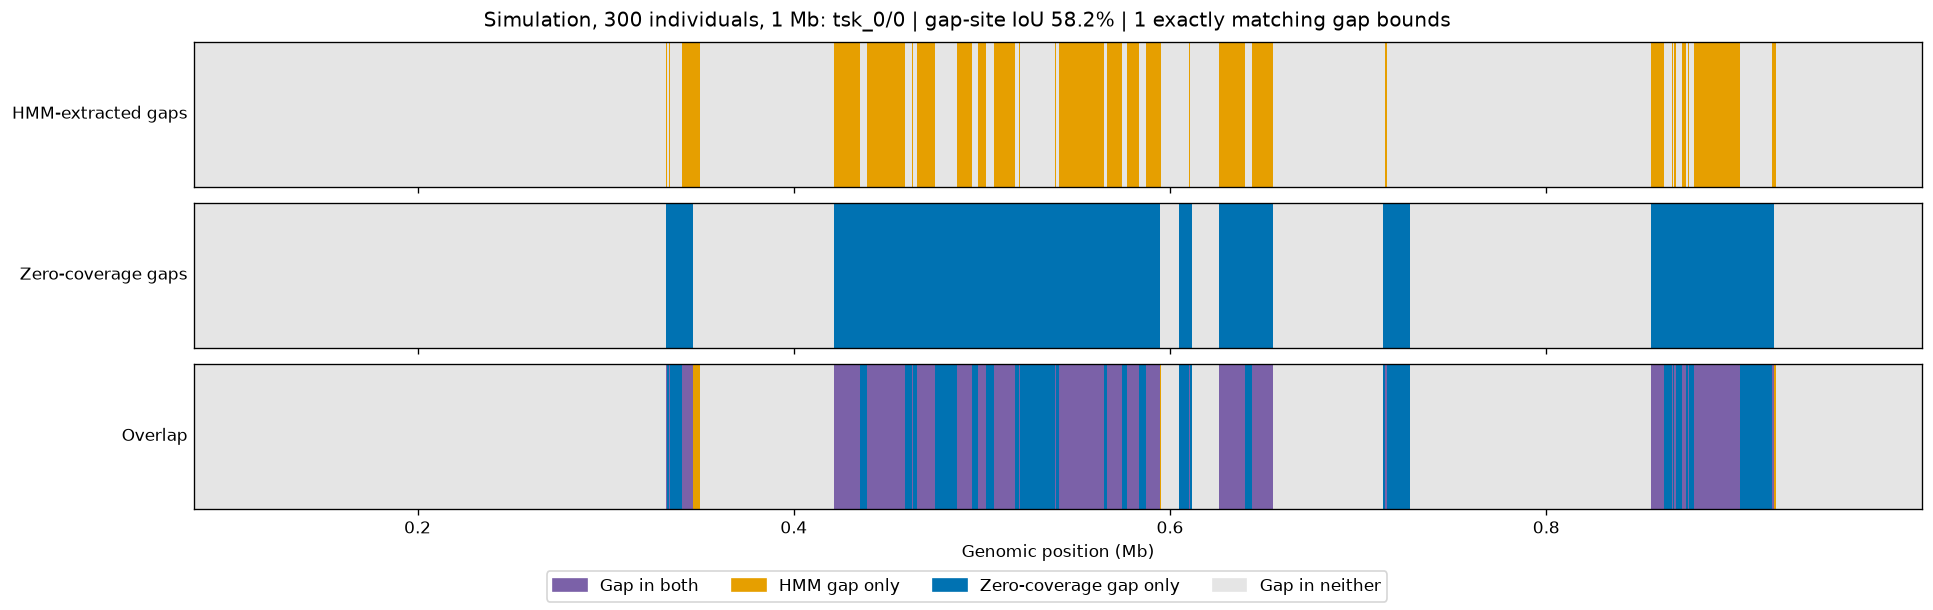

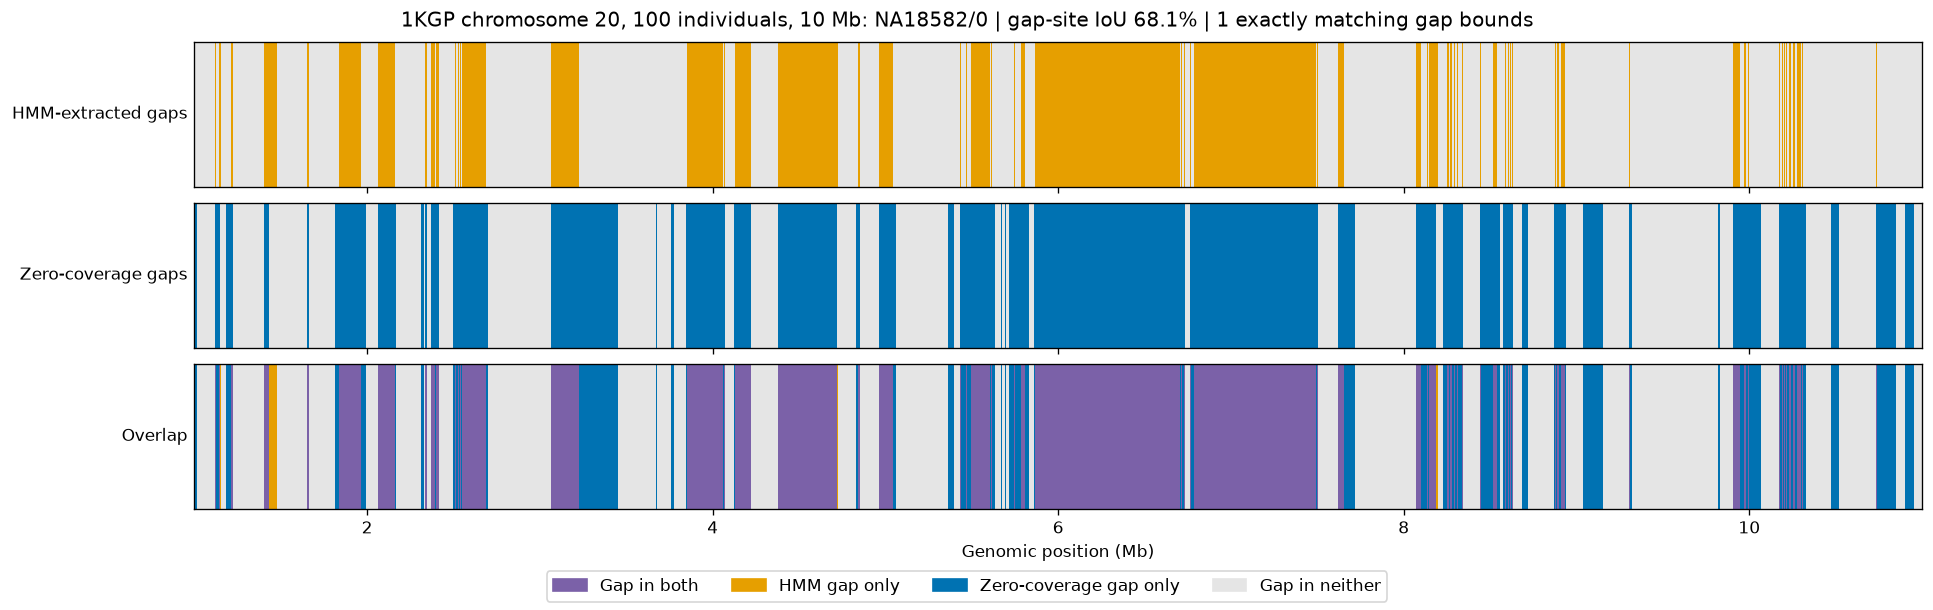

In [15]:
nb_plot.plot_gap_determination_4(
    datasets=datasets, gap_comparisons=gap_comparisons, handles=handles, figsize=(12, 6)
)

HMM-only gap sites have at least one zero-mismatch focal interval available,
but the reduced HMM's selected parent was not accepted there. Zero-coverage-only
gap sites were accepted by the original stitching calculation despite lying
outside every focal-anchored zero-mismatch interval. These are direct evidence
that the two acceptance definitions differ, rather than an endpoint plotting
convention. The comparison keeps their original definitions intact.

In [16]:
for dataset in datasets:
    results = gap_comparisons[dataset.name]
    hmm_count = sum((result.summary["hmm_num_gaps"] for result in results))
    zero_count = sum((result.summary["zero_coverage_num_gaps"] for result in results))
    intersection = sum((result.summary["overlap_sites"] for result in results))
    hmm_only = sum((result.summary["hmm_only_gap_sites"] for result in results))
    zero_only = sum((result.summary["zero_only_gap_sites"] for result in results))
    iou = intersection / (intersection + hmm_only + zero_only)
    print(
        f"{dataset.label}: {hmm_count} HMM gaps versus {zero_count} zero-coverage gaps; site-weighted gap IoU {iou:.1%}; {zero_only:,} accepted sites outside all anchored exact intervals."
    )
print("CSV directory (relative to diagnostics YAML):", config["gap_comparison_dir"])

Simulation, 300 individuals, 1 Mb: 148 HMM gaps versus 22 zero-coverage gaps; site-weighted gap IoU 70.6%; 2,628 accepted sites outside all anchored exact intervals.
1KGP chromosome 20, 100 individuals, 10 Mb: 1105 HMM gaps versus 221 zero-coverage gaps; site-weighted gap IoU 57.4%; 25,734 accepted sites outside all anchored exact intervals.
CSV directory (relative to diagnostics YAML): ../../data/ch5_stitching_gap_diagnostics


## Interpretation and next diagnostic questions

The saved comparison tables report identical mutation records for these runs:
both paths have zero called mismatches. Their score differences therefore come
entirely from extra switches in the stitched paths. Report their net count as
a proportion of stitched switches rather than the raw score difference.
Parent disagreement remains
meaningful even when the observed alleles are equally well explained.

Use the switch decomposition and gap zooms to identify seams worth a boundary-
conditioned follow-up. Use the focal-disagreement zooms to inspect fixed pieces
that already select a different ancestor than the full HMM. A boundary-conditioned
gap matcher cannot change those retained site parents, so recovering the exact
full parent path would also require reconsidering which focal pieces are fixed.
These diagnostics compare the two saved paths; they do not establish which
copying genealogy is biologically correct or exclude equivalent optimal paths.

In [17]:
assert summary.mutations_identical.all()
assert (summary.full_mismatches == 0).all()
assert (summary.stitched_mismatches == 0).all()
assert (summary.num_extra_switches > 0).all()
for dataset in datasets:
    case = dataset.primary
    full_counts = nb_utils.switch_breakdown(case, case.full_parents)
    stitched_counts = nb_utils.switch_breakdown(case, case.stitched_parents)
    extra = stitched_counts - full_counts
    print(
        f"{dataset.label}, {case.label}: parent agreement {case.summary['fraction_parent_agreement']:.1%}; extra switches {int(extra.sum())} = focal {extra[0]} + gaps {extra[1]} + seams {extra[2]}; extra switch prop. {case.summary['extra_switch_fraction']:.1%}"
    )

Simulation, 300 individuals, 1 Mb, tsk_0/0: parent agreement 57.4%; extra switches 93 = focal 4 + gaps -1 + seams 90; extra switch prop. 75.6%
1KGP chromosome 20, 100 individuals, 10 Mb, NA18582/0: parent agreement 68.4%; extra switches 796 = focal -18 + gaps -10 + seams 824; extra switch prop. 76.9%
